# Movimiento browniano con todas las grabaciones, separando por radio

Hasta acá el movimiento browniano se había medido con las dos grabaciones sin láser. Pero en **todas** las grabaciones con la pinza prendida hay, además de la partícula atrapada, partículas libres en el campo. Este notebook las junta todas para tener más estadística y separa el resultado **por tamaño de partícula** y **por día** (12/11 y 19/11: son dos muestras).

Qué se hace, en orden:

1. Se listan las grabaciones que se pueden usar.
2. En las grabaciones donde la platina da patadas, se usan solo los tramos en que está quieta.
3. Se mide el coeficiente de difusión $D$ de cada partícula de una forma en la que no entra el arrastre del líquido.
4. Se eligen las partículas libres (fuera la atrapada, las pegadas al vidrio, los choques y los agregados).
5. Se separan por radio aparente.
6. $D$ por clase de radio y por muestra, y si las dos muestras son compatibles.
7. $D$ contra el radio: ¿sigue Stokes–Einstein ($D \propto 1/R$)?
8. ¿Es browniano? Cinco chequeos.
9. Arrastre y viscosidad por día, y comparación con lo que ya había.

Entradas: `datos/<grabación>/trayectorias.csv`, `tiempo.csv`, `radios.csv` y, con láser, `platina.csv` y `atrapada.csv`. Funciones en `codigo/browniano_todas.py`. Salidas: `resultados/todas_*.csv` y `figuras/todas las grabaciones/` (SVG).

Los videos de otros grupos (`GROS BROWNIANO`, `CHICAS BROWNIANO`) **no entran**: no se conoce su escala ni su muestra y no se pueden mezclar con los nuestros.

Los números que aparecen en los textos son de la corrida del 19/11/2026, con las 17 grabaciones (11 del 12/11 y 6 del 19/11). Si se vuelve a convertir algún video o se agregan grabaciones, valen las tablas y el resumen del final, que se calculan solos, y hay que revisar los textos.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "codigo")))      # las funciones están en pinzas ópticas/codigo/
from carpetas import figuras, resultados                            # dónde va cada cosa, por objetivo
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats, optimize
import browniano_todas as bt
from pinzas_datos import RAIZ, DATOS, CATALOGO, ESCALA_UM
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)
from pinzas import fisica
warnings.filterwarnings("ignore", category=RuntimeWarning)      # promedios de columnas vacías

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE, AZUL = "#2A9D8F", "#E76F51", "#264653", "#4C72B0"
MARCA = dict(ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, zorder=3)
LEYENDA = dict(facecolor="white", framealpha=0.9)
FIGURAS = figuras("browniano", "todas las grabaciones")
SALIDA = resultados("browniano")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

# ---- decisiones (cada una se explica en su sección)
LARGO_MIN = 200            # cuadros que tiene que tener una trayectoria (sin colisión y con la platina quieta)
CERCA_LASER_PX = 60        # px: una trayectoria que pasa a menos de esto del láser no cuenta como libre
ALFA_MIN = 0.7             # pendiente log-log mínima para que cuente como libre (las pegadas dan cerca de 0)
V_IMAGEN_MAX = 0.5         # µm/s: si la imagen entera se corre más rápido que esto, la grabación no se usa
BORDES_CLASE = [1.2, 1.6, 2.1]                                  # µm de radio aparente (sección 5)
CLASES = ["chica", "intermedia", "nominal", "grande"]
T_AMB, ERR_T = 296.15, 3.0       # K: 23 °C SUPUESTO, ± 3 °C
R_NOMINAL = 1.5                  # µm: radio nominal de las partículas (3 µm de diámetro)
KT = fisica.KB * T_AMB           # J
# lo que se vio mirando las imágenes de las dos grabaciones sin láser (comparación de mediciones, DUDAS 13)
A_MANO = {"BROWNIANO 1": {6: "agregado", 40: "agregado", 42: "agregado", 24: "fuera de foco", 26: "fuera de foco", 27: "fuera de foco"},
          "BROWNIANO 2": {3: "agregado", 34: "agregado", 15: "fuera de foco"}}
# pares y racimos de partículas pegadas que se ven en los recortes de las grabaciones con láser
# (datos/<grabación>/imágenes de control/radios/recortes.png), mirados el 19/11/2026. OJO: los números
# de partícula son los de la conversión actual; si se vuelve a convertir un video, hay que mirarlos de nuevo.
AGREGADOS_VISTOS = {"BARRIDO 1": [27], "LASER 5": [4], "BARRIDO POTENCIAS 2": [8, 14, 32, 38],
                    "BARRIDO STEPSIZE": [78, 143, 147, 175, 176], "BARRIDO STEPSIZE 2": [12], "BARRIDO STEPSIZE 3": [250, 541, 644],
                    "BARRIDO POTENCIAS 4": [14, 55, 64], "BARRIDO POTENCIAS 5": [30], "BARRIDO POTENCIAS 6": [2],
                    "BARRIDO POTENCIAS 7": [5, 30, 34, 61, 107], "BARRIDO POTENCIAS 8": [7, 14, 32, 36, 50, 63, 80]}
for nombre, lista in AGREGADOS_VISTOS.items():
    A_MANO[nombre] = {p: "agregado" for p in lista}
# cómo se dibuja cada muestra (color, marcador, nombre) y cada clase de radio
ESTILO = {"12/11": (SERIE1, "o", "Muestra del 12/11"),
          "19/11": (SERIE2, "D", "Muestra del 19/11"),
          "12/11, muestra de BROWNIANO 1": (AZUL, "s", "Muestra de BROWNIANO 1")}
ESTILO_CLASE = {"nominal": (SERIE1, "o", "Partículas nominales"), "intermedia": (SERIE2, "D", "Partículas intermedias"),
                "chica": (AZUL, "s", "Partículas chicas")}


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".svg"), bbox_inches="tight")


def csv(tabla, nombre):
    tabla.to_csv(os.path.join(SALIDA, nombre), index=False, float_format="%.5g")


def archivo(muestra):
    # '12/11' → '12-11' (para nombres de archivo)
    return muestra.split(",")[0].replace("/", "-")

## 1. Qué grabaciones entran

Se toman las dos sin láser y todas las del catálogo de grabaciones con láser (`codigo/pinzas_datos.py`). Una grabación entra si ya tiene sus tablas en `datos/<grabación>/` (`trayectorias.csv`, `tiempo.csv` y `radios.csv`; `platina.csv` si es de patadas); si todavía no las tiene, se avisa y se saltea (al volver a ejecutar el notebook entra sola).

Las grabaciones se agrupan por **muestra**: la del 12/11 (la de la pinza, que es también la de `BROWNIANO 2`), la de `BROWNIANO 1` (otra mezcla, anotada con signo de pregunta) y la del 19/11 (no anotada). El día sale de `datos/catalogo.csv`.

In [2]:
GRAB, filas = {}, []
for nombre in bt.grabaciones():
    falta = bt.faltan(nombre)
    if falta:
        print("AVISO: %s todavía no entra (falta %s)" % (nombre, ", ".join(falta)))
        continue
    g = bt.cargar(nombre)
    if g["laser"] and not g["tiene_atrapada"]:
        print("AVISO: %s no tiene atrapada.csv: la atrapada se saca solo por su distancia al láser" % nombre)
    if g["laser"] and g["platina"] is None:
        print("AVISO: %s no tiene platina.csv: no se puede verificar que la platina esté quieta (es un barrido de potencia: se supone quieta)" % nombre)
    GRAB[nombre] = g
    c = g["cuenta"]
    filas.append({"grabación": nombre, "día": g["dia"], "muestra": g["muestra"], "láser": "sí" if g["laser"] else "no", "cuadros": g["n"],
                  "cuadros/s": 1 / g["dt"], "duración [s]": g["n"] * g["dt"], "trayectorias": c["trayectorias"],
                  "con radio medido": c["con_radio"], "posiciones medidas": c["posiciones"]})
tabla_grab = pd.DataFrame(filas)
print("%d grabaciones, %.0f minutos de video en total" % (len(GRAB), tabla_grab["duración [s]"].sum() / 60))
print(tabla_grab.groupby("día").agg(grabaciones=("grabación", "size"), minutos=("duración [s]", lambda s: s.sum() / 60)).round(0))
tabla_grab.round(2)

17 grabaciones, 76 minutos de video en total
       grabaciones  minutos
día                        
12/11           11     52.0
19/11            6     24.0


,grabación,día,muestra,láser,cuadros,cuadros/s,duración [s],trayectorias,con radio medido,posiciones medidas
0,BROWNIANO 1,12/11,"12/11, muestra de BROWNIANO 1",no,5102,10.02,509.18,43,11,13203
1,BROWNIANO 2,12/11,12/11,no,2121,10.02,211.66,43,22,14930
2,LASER NE,12/11,12/11,sí,2258,10.02,225.30,158,58,19868
3,BARRIDO 1,12/11,12/11,sí,3219,10.02,321.23,364,256,56540
4,MUEVO A MANO,12/11,12/11,sí,1209,10.02,120.65,216,60,8289
5,BARRIDO 2,12/11,12/11,sí,1753,10.02,174.97,320,107,14501
6,LASER 5,12/11,12/11,sí,3165,13.13,241.09,63,30,27017
7,BARRIDO POTENCIAS 2,12/11,12/11,sí,3006,12.50,240.46,43,26,26113
8,BARRIDO STEPSIZE,12/11,12/11,sí,3834,12.50,306.67,196,97,27148
9,BARRIDO STEPSIZE 2,12/11,12/11,sí,3376,12.50,270.01,132,98,24927


**Qué se ve.** Entran las 17 grabaciones: 11 del 12/11 (52 minutos de video) y 6 del 19/11 (24 minutos).

Las del 19/11 son barridos de potencia con la platina quieta, a 13.75 cuadros por segundo y con 30.5 ms de exposición. Se supone la misma escala (94.61 nm por píxel). Su muestra no está anotada: van como grupo aparte.

«Con radio medido» son las trayectorias de 100 cuadros o más: a esas `codigo/medir_radios.py` les midió el radio aparente sobre la imagen. Las más cortas no se usan.

## 2. Solo con la platina quieta

En las grabaciones con patadas la platina se mueve de golpe varios µm. Ahí las partículas no difunden: se van con el líquido. Entonces:

- `platina.csv` dice cuánto se corrió **toda la imagen** de un cuadro al siguiente. Una **patada** es una seguidilla de cuadros en que la imagen se corre más de 1.5 px por cuadro y que recorre más de 8 px en total, o que tiene algún paso de más de 3 px. Es el criterio de la tabla de patadas del objetivo 2, un poco más estricto (cuenta también los ida y vuelta y los saltos sueltos).
- Se descartan los cuadros de cada patada y 5 cuadros antes y después. Lo que queda entre patadas son los **tramos quietos**.
- **Nunca se calcula un desplazamiento entre dos cuadros de tramos distintos.**
- También se descartan los archivos donde el disco hizo una pausa al grabar (faltan cuadros y no se sabe cuáles): uno en `BROWNIANO 1`, uno en `BARRIDO 1` y uno en `BARRIDO STEPSIZE 3`.

**Verificación.** En los cuadros que quedan se mira cuánto se mueve la imagen entera. Tres números: la velocidad media de la imagen, el desvío de su paso de un cuadro al siguiente (desvío estándar: el tamaño típico de las fluctuaciones) y el mayor paso. Si la imagen entera viaja a más de 0.5 µm/s, la grabación no se usa.

AVISO: LASER NE no se usa: la imagen entera se corre a 0.7 µm/s aun entre patadas
figura: BARRIDO STEPSIZE 2 (14 patadas)


,grabación,patadas,tramos quietos,cuadros que se usan [%],tramo más largo [s],se usa,velocidad de la imagen [µm/s],desvío del paso de la imagen [nm],mayor paso de la imagen [px]
0,BROWNIANO 1,0,2,93.45,433.33,sí,NaN,NaN,NaN
1,BROWNIANO 2,0,1,100.00,211.66,sí,NaN,NaN,NaN
2,LASER NE,57,7,34.19,20.16,NO,0.73,48.24,2.99
3,BARRIDO 1,17,14,88.75,61.37,sí,0.12,29.44,2.31
4,MUEVO A MANO,39,4,38.46,11.58,sí,0.09,41.39,2.68
5,BARRIDO 2,33,7,56.30,15.97,sí,0.06,39.50,2.98
6,LASER 5,4,5,97.69,196.60,sí,0.19,43.42,2.34
7,BARRIDO POTENCIAS 2,0,1,100.00,240.46,sí,0.13,31.95,1.96
8,BARRIDO STEPSIZE,27,13,86.80,97.34,sí,0.11,38.10,2.85
9,BARRIDO STEPSIZE 2,14,15,94.08,44.39,sí,0.09,41.51,2.31


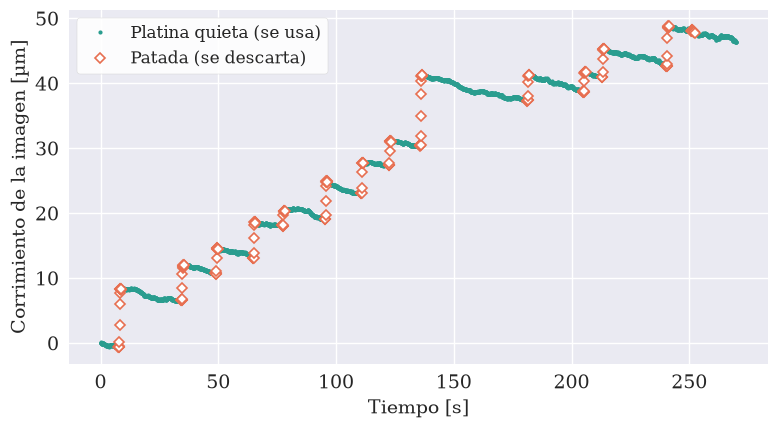

In [3]:
filas = []
for nombre, g in GRAB.items():
    usable = g["tramo"] >= 0
    largos = np.bincount(g["tramo"][usable]) if usable.any() else np.zeros(1)
    fila = {"grabación": nombre, "patadas": len(g["patadas"]), "tramos quietos": int((largos >= 40).sum()),
            "cuadros que se usan [%]": 100 * usable.mean(), "tramo más largo [s]": largos.max() * g["dt"]}
    g["v_imagen"] = np.nan
    if g["platina"] is not None:
        dx = g["platina"].dx_px.fillna(0).values[:g["n"]][usable]
        dy = g["platina"].dy_px.fillna(0).values[:g["n"]][usable]
        g["v_imagen"] = np.hypot(dx.mean(), dy.mean()) * ESCALA_UM / g["dt"]
        fila["velocidad de la imagen [µm/s]"] = g["v_imagen"]
        fila["desvío del paso de la imagen [nm]"] = 1e3 * ESCALA_UM * np.sqrt(0.5 * (dx.var() + dy.var()))
        fila["mayor paso de la imagen [px]"] = np.hypot(dx, dy).max()
    g["usar"] = not (g["v_imagen"] > V_IMAGEN_MAX)
    fila["se usa"] = "sí" if g["usar"] else "NO"
    filas.append(fila)
tabla_platina = pd.DataFrame(filas)
for nombre, g in GRAB.items():
    if not g["usar"]:
        print("AVISO: %s no se usa: la imagen entera se corre a %.1f µm/s aun entre patadas" % (nombre, g["v_imagen"]))

# una grabación de ejemplo: posición de la imagen en el tiempo
con_patadas = [n for n in GRAB if GRAB[n]["usar"] and GRAB[n]["patadas"]]
if con_patadas:
    ejemplo = "BARRIDO STEPSIZE 2" if "BARRIDO STEPSIZE 2" in con_patadas else con_patadas[0]
    g = GRAB[ejemplo]
    eje = "dy_px" if CATALOGO[ejemplo].get("eje") == "y" else "dx_px"
    t = np.arange(g["n"]) * g["dt"]
    pos = np.cumsum(g["platina"][eje].fillna(0).values[:g["n"]]) * ESCALA_UM
    usable = g["tramo"] >= 0
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(t[usable], pos[usable], "o", ms=3, color=SERIE1, zorder=3, label="Platina quieta (se usa)")
    ax.plot(t[~usable], pos[~usable], "D", ms=5, color=SERIE2, mfc="white", mew=1.2, zorder=3, label="Patada (se descarta)")
    ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("Corrimiento de la imagen [µm]")
    ax.legend(loc="upper left", fontsize=12, **LEYENDA)
    guardar(fig, "platina_tramos_quietos")
    print("figura: %s (%d patadas)" % (ejemplo, len(g["patadas"])))
tabla_platina.round(2)

**Qué se ve.**

- En las grabaciones que se usan, entre patadas la imagen entera se corre a menos de 0.25 µm/s y su paso de un cuadro al siguiente fluctúa 30 a 60 nm (alrededor de medio píxel); el mayor paso que queda es de menos de 3 px. Ese corrimiento lento **no es la platina**: es el líquido, que arrastra a las partículas libres (la correlación de imágenes sigue lo que se ve, y lo que se ve son partículas). Es parejo, y el método de la sección 3 lo saca.
- En los barridos de potencia figuran «patadas» aunque la platina no se tocó (4 en `LASER 5`, hasta 18 en los del 19/11): son seguidillas de ruido de la medición del corrimiento. Se descartan igual (2 a 10 % de los cuadros): el criterio prefiere tirar cuadros buenos antes que usar uno malo.
- **`LASER NE` queda afuera.** Durante toda la grabación la imagen entera viaja a 0.7 µm/s o más, cinco veces más que en las otras, y va cambiando. No hay tramos quietos donde medir.
- **`MUEVO A MANO` y `BARRIDO 2` entran pero no aportan**: la platina se movió tan seguido que el tramo quieto más largo dura 12 y 16 s, y ninguna trayectoria llega a los 200 cuadros que se piden (sección 4).
- La figura muestra una grabación con patadas: los escalones son las patadas (se descartan) y los tramos planos son los que se usan. La pendiente suave de los tramos planos es el arrastre del líquido.
- Las dos grabaciones sin láser no tienen `platina.csv`: ahí la platina no se tocó. El chequeo de que las partículas no se mueven todas juntas (sección 8) vale también para ellas.

## 3. Cómo se mide $D$ sin que entre el arrastre

El líquido arrastra a todas las partículas a unos 0.2 µm/s. Si no se saca, $D$ sale de más. Y hay otra trampa: cada posición se mide con un error de 20 a 95 nm (`0 - calibración y precisión`), que ensancha los pasos aunque la partícula no se mueva.

El método (`codigo/browniano_todas.py`, la misma idea que `potencia.difusion_libre`):

1. Cada tramo quieto se parte en **trozos de 6 s**.
2. Para cada retardo (1, 2, 3 y 4 cuadros) se toman los desplazamientos de la partícula y se calcula su **varianza** dentro del trozo: el promedio del cuadrado de lo que cada desplazamiento se aparta del desplazamiento medio del trozo. El desplazamiento medio es el arrastre; al restarlo, no entra.
3. Para un browniano esa varianza crece en línea recta con el retardo: $V(\tau) = 2D\tau + 2\sigma^2$, por eje. **$D$ es la mitad de la pendiente.** El error de localización $\sigma$ solo sube la recta entera (la ordenada), no cambia la pendiente. Por eso $D$ no se saca del ancho del histograma de pasos.
4. $D$ de la partícula es el promedio de $x$ e $y$. Su **error** sale de repetir la cuenta 300 veces eligiendo trozos al azar (con repetición) y ver cuánto cambia el resultado (*bootstrap*).

**Chequeo del método.** Se simulan brownianos con $D$ conocido (0.08 µm²/s), con un arrastre de 0.2 µm/s y un error de localización de 50 nm, en los mismos cuadros, huecos y tramos que las partículas reales de dos grabaciones (una sin patadas y la que más patadas tiene). Si el método está bien, devuelve 0.08.

In [4]:
rng = np.random.default_rng(2026)
D_SIM = 0.08
filas = []
for nombre in [n for n in ("BROWNIANO 2", "BARRIDO STEPSIZE 3") if n in GRAB]:
    g = GRAB[nombre]
    for k in np.flatnonzero(np.isfinite(g["X"]).sum(0) >= LARGO_MIN):
        for rep in range(6):
            x, y = bt.simular_como(g, k, D_SIM, ruido_um=0.05, v_um_s=0.2, rng=rng)
            d = bt.difusion(x, y, g["tramo"], g["dt"], n_boot=100, rng=rep)
            filas.append(dict(grabacion=nombre, k=k, D=d["D"], err=d["err_D"]))
sim = pd.DataFrame(filas)
for nombre, s in sim.groupby("grabacion", sort=False):
    print("%s: %d trayectorias simuladas | D medido / D verdadero = %.3f ± %.3f | dispersión real de D %.4f, error que da el bootstrap %.4f µm²/s"
          % (nombre, len(s), s.D.mean() / D_SIM, s.D.std() / np.sqrt(len(s)) / D_SIM, s.groupby("k").D.std().mean(), s.err.mean()))

BROWNIANO 2: 132 trayectorias simuladas | D medido / D verdadero = 1.009 ± 0.010 | dispersión real de D 0.0083, error que da el bootstrap 0.0077 µm²/s
BARRIDO STEPSIZE 3: 372 trayectorias simuladas | D medido / D verdadero = 1.006 ± 0.007 | dispersión real de D 0.0101, error que da el bootstrap 0.0086 µm²/s


**Qué se ve.** El método devuelve el $D$ que se puso, dentro de 1 %, con arrastre y con error de localización, en tramos largos y en tramos cortos entre patadas. El error que da el bootstrap es parecido a lo que de verdad se dispersa $D$ entre repeticiones (7 a 15 % menor): se le puede creer.

## 4. Una fila por partícula, y cuáles son libres

Para cada trayectoria con radio medido se calcula $D$ (si tiene cuadros suficientes) y se le pone un **motivo**: `libre`, o por qué se descarta. En este orden:

| Motivo | Criterio |
|---|---|
| imagen moviéndose | la grabación no pasó la verificación de la sección 2 |
| atrapada o cerca del láser | figura como atrapada en `atrapada.csv`, o pasó a menos de 60 px (5.7 µm) del láser |
| corta | menos de 200 cuadros usables (sin colisión y con la platina quieta); son 15 a 20 s |
| pegada al vidrio | no se aleja con el tiempo: pendiente log-log menor que 0.7 |
| agregado o fuera de foco | lo que se vio mirando las imágenes: en `BROWNIANO 1` y `2`, la lista del análisis anterior; en las grabaciones con láser, los pares y racimos de partículas pegadas entre sí que se ven en los recortes (`datos/<grabación>/imágenes de control/radios/recortes.png`) |

Tres aclaraciones:

- **Colisiones.** Los cuadros en que dos partículas están a menos de 2.5 radios no se usan (la posición es poco confiable). Se descartan los cuadros, no la partícula.
- **Pendiente log-log ($\alpha$).** Es cuánto crece la varianza del desplazamiento al aumentar el retardo, en escala logarítmica. Un browniano libre da 1 (la varianza se duplica cuando el retardo se duplica). Una partícula pegada da cerca de 0 (no se aleja más por esperar más). Se mide entre 4 y 20 cuadros de retardo.
- **Agregados.** Se miraron los recortes de todas las trayectorias que habían quedado como libres en las grabaciones con láser (seis recortes de cada una, repartidos en el tiempo). Se marcó como agregado solo lo que aparece pegado a otra partícula en todos o casi todos los recortes; una vecina que pasa cerca en uno o dos no cuenta. Dos partículas pegadas difunden como una más grande: no son «una partícula».

en las grabaciones que se usan: 429855 posiciones medidas; 3.3 % descartadas por colisión y 7.4 % por la platina
trayectorias con radio medido: 1211
libres, muestra 12/11, muestra de BROWNIANO 1: 4 en 1 grabaciones, 11 minutos de trayectoria sumados
libres, muestra 12/11: 141 en 7 grabaciones, 115 minutos de trayectoria sumados
libres, muestra 19/11: 109 en 6 grabaciones, 137 minutos de trayectoria sumados
de las 115 pegadas, 9 tienen D > 0.05 µm²/s; de las 254 libres, 1 tienen D < 0.03 µm²/s
agregados vistos en los recortes de las grabaciones con láser: 32 (12/11: 15, 19/11: 17); D medio 0.055 µm²/s, radio aparente medio 1.97 µm


motivo,trayectorias,sin radio (menos de 100 cuadros),libre,pegada al vidrio,atrapada o cerca del láser,agregado o fuera de foco,corta,imagen moviéndose
grabacion,,,,,,,,
BROWNIANO 1,43,32,4,1,0,6,0,0
BROWNIANO 2,43,21,19,1,0,2,0,0
LASER NE,158,100,0,0,0,0,0,58
BARRIDO 1,364,108,21,58,11,1,165,0
MUEVO A MANO,216,156,0,0,7,0,53,0
BARRIDO 2,320,213,0,0,7,0,100,0
LASER 5,63,33,13,0,3,1,13,0
BARRIDO POTENCIAS 2,43,17,11,2,1,4,8,0
BARRIDO STEPSIZE,196,99,21,14,11,5,46,0


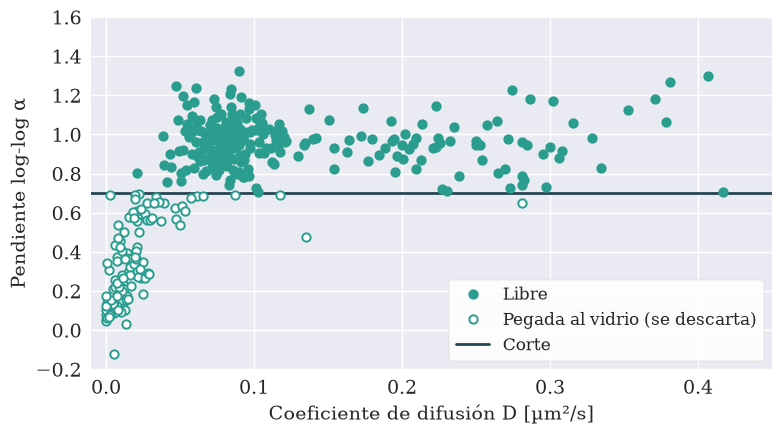

In [5]:
tabla = pd.concat([bt.por_particula(g, LARGO_MIN) for g in GRAB.values()], ignore_index=True)


def motivo(f):
    if not GRAB[f.grabacion]["usar"]:
        return "imagen moviéndose"
    if f.en_atrapada or f.dist_laser_um < CERCA_LASER_PX * ESCALA_UM:
        return "atrapada o cerca del láser"
    if f.cuadros < LARGO_MIN:
        return "corta"
    if not (f.alfa >= ALFA_MIN) or not (f.D_um2_s > 0):
        return "pegada al vidrio"
    if f.particula in A_MANO.get(f.grabacion, {}):
        return "agregado o fuera de foco"
    return "libre"


tabla["motivo"] = tabla.apply(motivo, axis=1)
es_libre = tabla.motivo == "libre"
tabla["clase"] = ""
tabla.loc[es_libre, "clase"] = np.array(CLASES)[np.digitize(tabla.R_ap_um[es_libre], BORDES_CLASE)]
libres = tabla[es_libre]

ORDEN = ["libre", "pegada al vidrio", "atrapada o cerca del láser", "agregado o fuera de foco", "corta", "imagen moviéndose"]
cuenta = pd.crosstab(tabla.grabacion, tabla.motivo).reindex(index=list(GRAB), columns=ORDEN, fill_value=0)
cuenta.insert(0, "trayectorias", [GRAB[n]["cuenta"]["trayectorias"] for n in cuenta.index])
cuenta.insert(1, "sin radio (menos de 100 cuadros)", [GRAB[n]["cuenta"]["trayectorias"] - GRAB[n]["cuenta"]["con_radio"] for n in cuenta.index])
cuenta.loc["TOTAL"] = cuenta.sum()
usadas = [n for n in GRAB if GRAB[n]["usar"]]
pos = sum(GRAB[n]["cuenta"]["posiciones"] for n in usadas)
print("en las grabaciones que se usan: %d posiciones medidas; %.1f %% descartadas por colisión y %.1f %% por la platina"
      % (pos, 100 * sum(GRAB[n]["cuenta"]["con_colision"] for n in usadas) / pos, 100 * sum(GRAB[n]["cuenta"]["con_platina_movida"] for n in usadas) / pos))
print("trayectorias con radio medido: %d" % len(tabla))
for m, s in libres.groupby("muestra", sort=False):
    print("libres, muestra %s: %d en %d grabaciones, %.0f minutos de trayectoria sumados"
          % (m, len(s), s.grabacion.nunique(), sum(s.cuadros[s.grabacion == n].sum() * GRAB[n]["dt"] for n in GRAB) / 60))
pegadas = tabla[tabla.motivo == "pegada al vidrio"]
agregados = tabla[(tabla.motivo == "agregado o fuera de foco") & ~tabla.grabacion.isin(["BROWNIANO 1", "BROWNIANO 2"])]
print("de las %d pegadas, %d tienen D > 0.05 µm²/s; de las %d libres, %d tienen D < 0.03 µm²/s"
      % (len(pegadas), (pegadas.D_um2_s > 0.05).sum(), len(libres), (libres.D_um2_s < 0.03).sum()))
print("agregados vistos en los recortes de las grabaciones con láser: %d (12/11: %d, 19/11: %d); D medio %.3f µm²/s, radio aparente medio %.2f µm"
      % (len(agregados), (agregados.muestra == "12/11").sum(), (agregados.muestra == "19/11").sum(), agregados.D_um2_s.mean(), agregados.R_ap_um.mean()))

# libres y pegadas en un gráfico: cuánto difunden y cuánto se alejan
fig, ax = plt.subplots(figsize=(8, 4.5))
for mot, mfc, etiqueta in (("libre", SERIE1, "Libre"), ("pegada al vidrio", "white", "Pegada al vidrio (se descarta)")):
    s = tabla[tabla.motivo == mot]
    ax.plot(s.D_um2_s, s.alfa, "o", ms=6, mew=1.4, color=SERIE1, mec=SERIE1, mfc=mfc, zorder=3, label=etiqueta)
ax.axhline(ALFA_MIN, color=AJUSTE, lw=2, zorder=2, label="Corte")
ax.set_xlim(-0.01, 0.45); ax.set_ylim(-0.2, 1.6)
ax.set_xlabel(r"Coeficiente de difusión $D$ [µm²/s]"); ax.set_ylabel(r"Pendiente log-log $\alpha$")
ax.legend(loc="lower right", fontsize=12, **LEYENDA)
guardar(fig, "libres_y_pegadas")
cuenta

**Qué se ve.**

- De 1211 trayectorias con radio medido quedan **254 libres**: 141 de la muestra del 12/11 (7 grabaciones, 115 minutos de trayectoria sumados), 109 de la del 19/11 (6 grabaciones, 137 minutos) y 4 de `BROWNIANO 1`. La mayoría de las descartadas son cortas (670): en las grabaciones con patadas cada patada corta el seguimiento, y la misma partícula vuelve a aparecer con otro número.
- **Pegadas al vidrio** (115): casi todas en las grabaciones con patadas del 12/11 (ahí el fondo no las borra); el 19/11 hay 6. En la figura son una nube aparte: casi no difunden ($D$ < 0.03 µm²/s) y no se alejan ($\alpha$ < 0.5). Tampoco las arrastra el líquido. Las libres están alrededor de $\alpha$ = 1.
- El corte en $\alpha$ = 0.7 es el del análisis de patadas (`fuerza y pozo`). No es perfecto: 9 de las descartadas difunden normalmente (pueden ser libres con un $\alpha$ medido con ruido) y 1 de las libres casi no difunde. No se corrigen a mano.
- **Agregados.** En los recortes de las grabaciones con láser se vieron 32 pares o racimos entre las trayectorias que habían quedado como libres: 15 el 12/11 y 17 el 19/11. Difunden más despacio (0.055 µm²/s en promedio) y se ven más grandes (radio aparente 1.97 µm): casi todos habían caído en la clase nominal o en la grande. Sacarlos sube el $D$ de las nominales 3 % el 12/11 y 7 % el 19/11 (sección 6).
- **Ojo con la cuenta de «partículas».** En las grabaciones con patadas la misma partícula puede aparecer en varias filas (una por tramo). Y el 19/11 las grabaciones 4, 5 y 6 comparten la partícula atrapada: es el mismo campo, y puede haber libres repetidas de una a otra. Por eso en la sección 6 el error de los promedios sale de la dispersión entre grabaciones.

## 5. Tamaños: el radio aparente

`radios.csv` trae el **radio aparente** de cada partícula: el radio donde el borde oscuro de su imagen vuelve a la mitad del brillo del fondo (`codigo/medir_radios.py`).

**No es el radio real: es mayor.** La partícula no se ve como un disco de borde nítido. La luz se difracta en su borde y alrededor queda un anillo oscuro más ancho que la partícula; el «borde» que se mide es el de ese anillo. Además el anillo se ensancha si la partícula está un poco fuera de foco, así que el radio aparente de una misma partícula cambia cuando sube o baja. Como radio absoluto vale dentro de 0.2 a 0.3 µm. Sirve para **comparar** partículas y separar tamaños.

Se mira el histograma de radios aparentes de todas las libres y se ponen los bordes de las clases con eso.

12/11: pico entre 1.7 y 1.8 µm (36 partículas); cae a menos de un cuarto por debajo de 1.6 y por encima de 2.0 µm
   partículas por barra de 0.1 µm, de 0.5 a 1.6 µm: 1 1 1 5 2 1 2 5 4 6 7
   clase nominal: 102 partículas, radio aparente 1.82 ± 0.11 µm (media y desvío)
19/11: pico entre 1.8 y 1.9 µm (24 partículas); cae a menos de un cuarto por debajo de 1.7 y por encima de 1.9 µm
   partículas por barra de 0.1 µm, de 0.5 a 1.6 µm: 0 6 2 4 6 12 6 6 6 4 4
   clase nominal: 52 partículas, radio aparente 1.82 ± 0.07 µm (media y desvío)
todas: pico entre 1.8 y 1.9 µm (59 partículas); cae a menos de un cuarto por debajo de 1.6 y por encima de 2.0 µm
   partículas por barra de 0.1 µm, de 0.5 a 1.6 µm: 1 7 3 9 8 13 8 12 10 10 11
   clase nominal: 157 partículas, radio aparente 1.82 ± 0.09 µm (media y desvío)
cuánto cambia el radio aparente de una misma partícula entre cuadros (mediana): 0.19 µm


clase,muestra,chica,intermedia,nominal,grande,libres
grabacion,,,,,,
BROWNIANO 1,"12/11, muestra de BROWNIANO 1",0,1,3,0,4
BROWNIANO 2,12/11,8,4,7,0,19
LASER NE,12/11,0,0,0,0,0
BARRIDO 1,12/11,0,6,14,1,21
MUEVO A MANO,12/11,0,0,0,0,0
BARRIDO 2,12/11,0,0,0,0,0
LASER 5,12/11,2,0,11,0,13
BARRIDO POTENCIAS 2,12/11,0,4,7,0,11
BARRIDO STEPSIZE,12/11,2,0,18,1,21


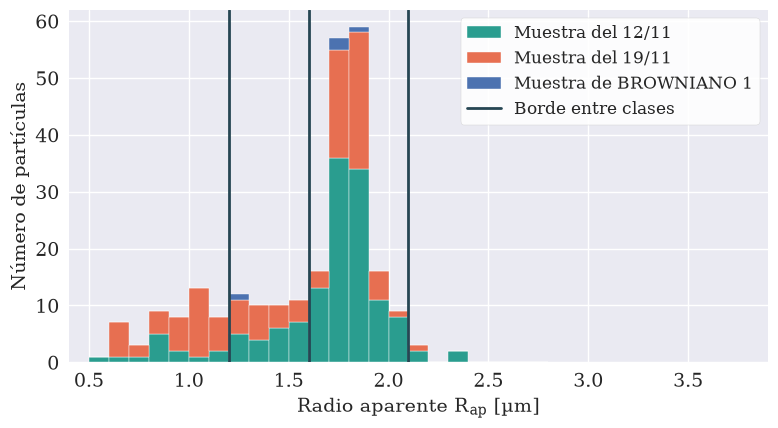

In [6]:
bordes = np.arange(0.5, 2.81, 0.1)
muestras = [m for m in ESTILO if (libres.muestra == m).any()]
muestras_dia = [m for m in muestras if "BROWNIANO" not in m]          # las muestras con muchas partículas (una por día)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([libres.R_ap_um[libres.muestra == m] for m in muestras], bins=bordes, stacked=True,
        color=[ESTILO[m][0] for m in muestras], label=[ESTILO[m][2] for m in muestras], zorder=2, edgecolor="white")
for r in BORDES_CLASE:
    ax.axvline(r, color=AJUSTE, lw=2, zorder=3, label="Borde entre clases" if r == BORDES_CLASE[0] else None)
ax.set_xlabel(r"Radio aparente $R_{ap}$ [µm]"); ax.set_ylabel("Número de partículas")
ax.set_xlim(0.4, 3.9); ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=12, **LEYENDA)
guardar(fig, "histograma_radios")

for m in muestras_dia + ["todas"]:
    s = libres if m == "todas" else libres[libres.muestra == m]
    cuentas, _ = np.histogram(s.R_ap_um, bordes)
    pico = int(np.argmax(cuentas))
    izq = pico
    while izq > 0 and cuentas[izq - 1] >= cuentas[pico] / 4:
        izq -= 1
    der = pico
    while der < len(cuentas) - 1 and cuentas[der + 1] >= cuentas[pico] / 4:
        der += 1
    nom = s[s.clase == "nominal"]
    print("%s: pico entre %.1f y %.1f µm (%d partículas); cae a menos de un cuarto por debajo de %.1f y por encima de %.1f µm"
          % (m, bordes[pico], bordes[pico + 1], cuentas[pico], bordes[izq], bordes[der + 1]))
    print("   partículas por barra de 0.1 µm, de 0.5 a 1.6 µm: %s" % " ".join("%d" % c for c in cuentas[:11]))
    print("   clase nominal: %d partículas, radio aparente %.2f ± %.2f µm (media y desvío)" % (len(nom), nom.R_ap_um.mean(), nom.R_ap_um.std()))
print("cuánto cambia el radio aparente de una misma partícula entre cuadros (mediana): %.2f µm" % libres.disp_R_ap_um.median())
por_clase = pd.crosstab(libres.grabacion, libres.clase).reindex(index=list(GRAB), columns=CLASES, fill_value=0)
por_clase.insert(0, "muestra", [GRAB[n]["muestra"] for n in por_clase.index])
por_clase["libres"] = por_clase[CLASES].sum(axis=1)
csv(por_clase.reset_index().rename(columns={"grabacion": "grabación"}), "todas_libres_por_clase.csv")
por_clase.loc["TOTAL"] = ["", *por_clase[CLASES + ["libres"]].sum()]
por_clase

**Qué se ve.**

- **El pico nominal es el mismo los dos días**: 1.7 a 1.9 µm, con radio aparente medio 1.82 µm el 12/11 y 1.82 µm el 19/11. Son las partículas de 1.5 µm de radio nominal, que se ven unos 0.3 µm más grandes. Que el pico caiga en el mismo lugar los dos días apoya que la escala del 19/11 es la misma (se había supuesto).
- A la izquierda del pico hay una población ancha de partículas más chicas, de 0.6 a 1.6 µm. El 12/11 son pocas (35) y hay un hueco entre 1.0 y 1.2 µm. **El 19/11 son muchas más (56, la mitad de las libres)**, con un máximo en 1.0 a 1.1 µm y sin hueco.
- **Clases** (bordes puestos mirando el histograma):
  - **chica**: $R_{ap}$ < 1.2 µm;
  - **intermedia**: 1.2 a 1.6 µm;
  - **nominal**: 1.6 a 2.1 µm: el pico, hasta donde el histograma cae a menos de un cuarto de su altura. El borde de 1.6 µm es el que ya usaba el análisis anterior;
  - **grande**: más de 2.1 µm. Sacados los agregados quedan solo 5: partículas fuera de foco o más grandes. Se informan aparte y no se interpretan.
- Lo seguro es el pico nominal. **«Chica» e «intermedia» no son dos tamaños definidos**: son las dos mitades de una población ancha de partículas más chicas que la nominal. Se separan porque difunden distinto (sección 6), no porque el histograma muestre dos picos.
- El radio aparente de una misma partícula cambia 0.2 µm entre cuadros (por el foco). Una partícula cerca de un borde puede haber caído en la clase de al lado.
- La tabla de arriba (libres por grabación y clase) queda en `resultados/todas_libres_por_clase.csv`.

## 6. $D$ por clase de radio y por muestra

Para cada muestra y cada clase se promedia el $D$ de sus partículas. Qué es cada columna:

- **± error**: la dispersión de $D$ entre partículas (desvío estándar) dividida por $\sqrt{n}$. Es cuánto se espera que cambie el promedio si se repitiera todo con otras partículas.
- **dispersión entre partículas**: el desvío estándar de $D$ entre partículas.
- **error típico de una partícula**: el error de medición de cada $D$ (el del bootstrap). Si la dispersión entre partículas es mayor que esto, las partículas **de verdad** tienen $D$ distintos (por tamaño o por altura sobre el vidrio), no es solo ruido de medición.
- **dispersión entre grabaciones**: el desvío estándar entre los promedios de cada grabación (si hay tres o más).
- **radio equivalente**: el radio que tendría que tener la partícula para difundir así según Stokes–Einstein, tomando como referencia a las nominales de la misma muestra con su radio nominal de 1.5 µm: $R_{eq} = 1.5\ \mathrm{µm} \times D_{nominal} / D$.

**¿Las dos muestras dan lo mismo?** Para cada clase se compara el $D$ del 12/11 con el del 19/11. Como error de cada uno se toma el mayor entre el estadístico y la dispersión entre grabaciones dividida por $\sqrt{\text{grabaciones}}$ (el estadístico solo es optimista: en las grabaciones con patadas una misma partícula se cuenta varias veces, y entre grabaciones cambia el foco). La diferencia se mide «en errores»: cuántas veces su propio error vale. Menos de 2 = compatibles; más de 3 = distintas.

Después se mira la clase nominal grabación por grabación, contra la hora en que se grabó, un día en cada panel.

muestra 12/11, nominales contra la hora: pendiente -0.0078 ± 0.0033 µm²/s por hora (2.4 veces su error); arrastre de 0.35 a 0.14 µm/s
   chi2 con D constante: 21.4 con 6 grados de libertad; con la recta: 10.0 con 5
muestra 19/11, nominales contra la hora: pendiente +0.0005 ± 0.0045 µm²/s por hora (0.1 veces su error); arrastre de 0.21 a 0.34 µm/s
   chi2 con D constante: 25.4 con 5 grados de libertad; con la recta: 25.3 con 4
nominales de la muestra 12/11: sin las 1 frenadas (D < 0.03) el promedio sería 0.0761 en vez de 0.0755 µm²/s; la mediana es 0.0756
   si no se hubieran sacado los agregados vistos en los recortes: 0.0730 µm²/s (113 trayectorias)
nominales de la muestra 19/11: sin las 0 frenadas (D < 0.03) el promedio sería 0.0906 en vez de 0.0906 µm²/s; la mediana es 0.0877
   si no se hubieran sacado los agregados vistos en los recortes: 0.0845 µm²/s (63 trayectorias)


,muestra,clase,partículas,grabaciones,radio aparente medio [µm],D [µm²/s],± error,dispersión entre partículas,error típico de una partícula,dispersión entre grabaciones,radio equivalente [µm],± radio equivalente
0,12/11,chica,13,4,0.8787,0.2579,0.0213,0.0768,0.0386,0.0613,0.4393,0.0378
1,12/11,intermedia,22,5,1.4260,0.1170,0.0119,0.0556,0.0148,0.0561,0.9682,0.1008
2,12/11,nominal,102,7,1.8153,0.0755,0.0018,0.0185,0.0090,0.0089,NaN,NaN
3,12/11,grande,4,3,2.2590,0.0903,0.0092,0.0184,0.0117,0.0215,1.2553,0.1318
4,19/11,chica,36,6,0.9485,0.2639,0.0106,0.0637,0.0333,0.0327,0.5148,0.0255
5,19/11,intermedia,20,6,1.3738,0.1800,0.0112,0.0501,0.0217,0.0430,0.7546,0.0518
6,19/11,nominal,52,6,1.8181,0.0906,0.0026,0.0188,0.0080,0.0094,NaN,NaN
7,19/11,grande,1,1,2.1107,0.0583,NaN,NaN,0.0046,NaN,2.3285,NaN
8,"12/11, muestra de BROWNIANO 1",intermedia,1,1,1.2417,0.1211,NaN,NaN,0.0156,NaN,0.6833,NaN
9,"12/11, muestra de BROWNIANO 1",nominal,3,1,1.8039,0.0552,0.0024,0.0041,0.0044,NaN,NaN,NaN


,qué se compara,partículas 12/11,D 12/11,± 12/11,partículas 19/11,D 19/11,± 19/11,cociente,diferencia en errores,D las dos juntas,± juntas
0,chica,13,0.2579,0.0307,36,0.2639,0.0133,1.0232,0.1790,0.2623,0.0146
1,intermedia,22,0.1170,0.0251,20,0.1800,0.0175,1.5383,2.0566,NaN,NaN
2,nominal,102,0.0755,0.0034,52,0.0906,0.0039,1.1989,2.9429,NaN,NaN
3,"nominal, solo barridos de potencia",18,0.0860,0.0040,52,0.0906,0.0039,1.0527,0.8198,0.0894,0.0032


,grabación,día,muestra,hora de inicio [h],partículas,radio aparente medio [µm],D [µm²/s],± error,dispersión entre partículas,error típico de una partícula,arrastre de las libres [µm/s]
0,BROWNIANO 1,12/11,"12/11, muestra de BROWNIANO 1",16.1064,3,1.8039,0.0552,0.0024,0.0041,0.0044,0.1793
1,BARRIDO 1,12/11,12/11,17.4897,14,1.7967,0.0869,0.0050,0.0185,0.0105,0.3540
2,BROWNIANO 2,12/11,12/11,17.8281,7,1.8187,0.0772,0.0050,0.0131,0.0056,0.3978
3,LASER 5,12/11,12/11,18.3758,11,1.7721,0.0910,0.0057,0.0188,0.0086,0.2896
4,BARRIDO POTENCIAS 2,12/11,12/11,19.0983,7,1.8580,0.0783,0.0038,0.0100,0.0044,0.2103
5,BARRIDO STEPSIZE,12/11,12/11,19.1814,18,1.8225,0.0668,0.0038,0.0163,0.0093,0.1820
6,BARRIDO STEPSIZE 2,12/11,12/11,19.3228,22,1.8241,0.0723,0.0030,0.0141,0.0090,0.1768
7,BARRIDO STEPSIZE 3,12/11,12/11,19.5775,23,1.8191,0.0698,0.0043,0.0206,0.0096,0.1354
8,BARRIDO POTENCIAS 3,19/11,19/11,16.1622,10,1.7646,0.0902,0.0030,0.0096,0.0076,0.2133
9,BARRIDO POTENCIAS 4,19/11,19/11,16.2664,10,1.8284,0.0828,0.0036,0.0113,0.0051,0.1869


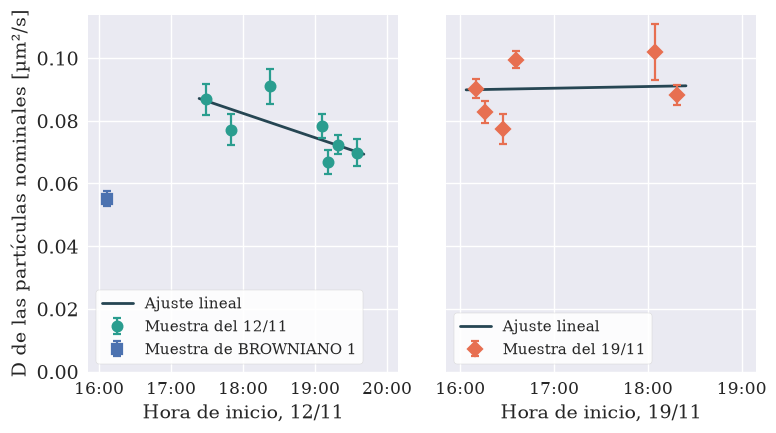

In [7]:
def resumir(s):
    D, e = s.D_um2_s.values, s.err_D_um2_s.values
    n = len(D)
    por_grab = s.groupby("grabacion").D_um2_s.mean()
    return {"partículas": n, "grabaciones": s.grabacion.nunique(), "radio aparente medio [µm]": s.R_ap_um.mean(), "D [µm²/s]": D.mean(),
            "± error": D.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan,
            "dispersión entre partículas": D.std(ddof=1) if n > 1 else np.nan,
            "error típico de una partícula": np.sqrt(np.mean(e ** 2)),
            "dispersión entre grabaciones": por_grab.std(ddof=1) if len(por_grab) > 2 else np.nan}


def D_de(sel):
    # D medio, su error (el mayor entre el estadístico y la dispersión entre grabaciones / raíz de grabaciones) y cuántas son
    r = resumir(sel)
    e = r["± error"]
    if np.isfinite(r["dispersión entre grabaciones"]):
        e = max(e, r["dispersión entre grabaciones"] / np.sqrt(r["grabaciones"]))
    return r["D [µm²/s]"], e, r["partículas"]


filas = []
for m in muestras:
    ref = libres[(libres.muestra == m) & (libres.clase == "nominal")]
    for clase in CLASES:
        s = libres[(libres.muestra == m) & (libres.clase == clase)]
        if len(s):
            r = resumir(s)
            if len(ref) > 1 and clase != "nominal":
                D0, e0 = ref.D_um2_s.mean(), ref.D_um2_s.std(ddof=1) / np.sqrt(len(ref))
                r["radio equivalente [µm]"] = R_NOMINAL * D0 / r["D [µm²/s]"]
                r["± radio equivalente"] = r["radio equivalente [µm]"] * np.hypot(e0 / D0, r["± error"] / r["D [µm²/s]"])
            filas.append({"muestra": m, "clase": clase, **r})
D_clase = pd.DataFrame(filas)
csv(D_clase, "todas_D_por_clase.csv")

# --- ¿las dos muestras (días) dan lo mismo?
DE_POTENCIA = [n for n in GRAB if CATALOGO.get(n, {}).get("tipo") == "potencia"]       # barridos de potencia: platina quieta
filas = []
if len(muestras_dia) == 2:
    ma, mb = muestras_dia

    def comparar(que, a, b):
        (Da, ea, na), (Db, eb, nb) = D_de(a), D_de(b)
        fila = {"qué se compara": que, "partículas %s" % ma: na, "D %s" % ma: Da, "± %s" % ma: ea, "partículas %s" % mb: nb, "D %s" % mb: Db, "± %s" % mb: eb,
                "cociente": Db / Da, "diferencia en errores": (Db - Da) / np.hypot(ea, eb)}
        if abs(fila["diferencia en errores"]) < 2:              # solo se juntan si son compatibles
            fila["D las dos juntas"], fila["± juntas"], _ = D_de(pd.concat([a, b]))
        return fila

    for clase in CLASES:
        a, b = libres[(libres.muestra == ma) & (libres.clase == clase)], libres[(libres.muestra == mb) & (libres.clase == clase)]
        if len(a) > 1 and len(b) > 1:
            filas.append(comparar(clase, a, b))
    nom = libres[(libres.clase == "nominal") & libres.grabacion.isin(DE_POTENCIA)]
    if (nom.muestra == ma).sum() > 1 and (nom.muestra == mb).sum() > 1:
        filas.append(comparar("nominal, solo barridos de potencia", nom[nom.muestra == ma], nom[nom.muestra == mb]))
compat = pd.DataFrame(filas)
for c in ("D las dos juntas", "± juntas"):
    if len(compat) and c not in compat:
        compat[c] = np.nan
csv(compat, "todas_compatibilidad_entre_dias.csv")

# --- la clase nominal, grabación por grabación, contra la hora de inicio (datos/catalogo.csv)
cat = pd.read_csv(os.path.join(DATOS, "catalogo.csv")).set_index("grabacion")


def hora(nombre):
    h = cat.hora_inicio.get(nombre) if "hora_inicio" in cat else None
    if not isinstance(h, str):
        return np.nan
    a = [int(v) for v in h.split(":")]
    return a[0] + a[1] / 60 + (a[2] if len(a) > 2 else 0) / 3600


filas = []
for nombre in GRAB:
    s = libres[(libres.grabacion == nombre) & (libres.clase == "nominal")]
    if len(s):
        filas.append({"grabación": nombre, "día": GRAB[nombre]["dia"], "muestra": GRAB[nombre]["muestra"], "hora de inicio [h]": hora(nombre),
                      **{k: v for k, v in resumir(s).items() if k not in ("grabaciones", "dispersión entre grabaciones")},
                      "arrastre de las libres [µm/s]": libres.v_um_s[libres.grabacion == nombre].median()})
D_grab = pd.DataFrame(filas).sort_values(["día", "hora de inicio [h]"]).reset_index(drop=True)
csv(D_grab, "todas_D_por_grabacion.csv")
for nombre in D_grab["grabación"][D_grab["hora de inicio [h]"].isna()]:
    print("AVISO: %s no tiene hora de inicio en datos/catalogo.csv: no entra en la figura" % nombre)

dias = [d for d in pd.unique(D_grab["día"]) if D_grab["hora de inicio [h]"][D_grab["día"] == d].notna().any()]
fig, axs = plt.subplots(1, len(dias), figsize=(8, 4.5), sharey=True, squeeze=False)
for ax, d in zip(axs[0], dias):
    sub = D_grab[(D_grab["día"] == d) & D_grab["hora de inicio [h]"].notna()]
    for m in [m for m in muestras if (sub.muestra == m).any()]:
        s = sub[sub.muestra == m]
        color, marca, etiqueta = ESTILO[m]
        ax.errorbar(s["hora de inicio [h]"], s["D [µm²/s]"], s["± error"], fmt=marca, color=color, mfc=color, mec=color, label=etiqueta, **MARCA)
    m0 = sub.muestra.value_counts().index[0]
    s = sub[(sub.muestra == m0) & (sub["partículas"] > 1)]
    if len(s) >= 4:
        h, D, e = s["hora de inicio [h]"].values, s["D [µm²/s]"].values, s["± error"].values
        p, cov = np.polyfit(h, D, 1, w=1 / e, cov=True)             # cov=True agranda los errores hasta que chi2 = grados de libertad
        chi2_cte = np.sum(((D - np.average(D, weights=1 / e ** 2)) / e) ** 2)
        chi2_recta = np.sum(((D - np.polyval(p, h)) / e) ** 2)
        hh = np.array([h.min() - 0.1, h.max() + 0.1])
        ax.plot(hh, np.polyval(p, hh), color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal")
        print("muestra %s, nominales contra la hora: pendiente %+.4f ± %.4f µm²/s por hora (%.1f veces su error); arrastre de %.2f a %.2f µm/s"
              % (m0, p[0], np.sqrt(cov[0, 0]), abs(p[0]) / np.sqrt(cov[0, 0]), s["arrastre de las libres [µm/s]"].iloc[0], s["arrastre de las libres [µm/s]"].iloc[-1]))
        print("   chi2 con D constante: %.1f con %d grados de libertad; con la recta: %.1f con %d" % (chi2_cte, len(h) - 1, chi2_recta, len(h) - 2))
    marcas_h = np.arange(np.floor(sub["hora de inicio [h]"].min()), np.ceil(sub["hora de inicio [h]"].max()) + 0.01, 1.0)
    ax.set_xticks(marcas_h, ["%d:00" % v for v in marcas_h], fontsize=12)
    ax.set_xlim(marcas_h[0] - 0.15, marcas_h[-1] + 0.15)
    ax.set_xlabel("Hora de inicio, " + d)
    ax.legend(loc="lower left", fontsize=11, **LEYENDA)
axs[0][0].set_ylabel(r"$D$ de las partículas nominales [µm²/s]")
axs[0][0].set_ylim(0, None)
guardar(fig, "D_nominales_por_grabacion")

for m in muestras_dia:
    nom_m = libres[(libres.muestra == m) & (libres.clase == "nominal")]
    print("nominales de la muestra %s: sin las %d frenadas (D < 0.03) el promedio sería %.4f en vez de %.4f µm²/s; la mediana es %.4f"
          % (m, (nom_m.D_um2_s < 0.03).sum(), nom_m.D_um2_s[nom_m.D_um2_s >= 0.03].mean(), nom_m.D_um2_s.mean(), nom_m.D_um2_s.median()))
    con = tabla[(tabla.muestra == m) & tabla.motivo.isin(["libre", "agregado o fuera de foco"]) & (tabla.R_ap_um >= BORDES_CLASE[1]) & (tabla.R_ap_um < BORDES_CLASE[2])]
    print("   si no se hubieran sacado los agregados vistos en los recortes: %.4f µm²/s (%d trayectorias)" % (con.D_um2_s.mean(), len(con)))
display(D_clase.round(4))
display(compat.round(4))
D_grab.round(4)

**Qué se ve.**

- **Cuanto más chica la partícula, más rápido difunde, los dos días.** El 12/11: nominales 0.076, intermedias 0.117 y chicas 0.258 µm²/s. El 19/11: nominales 0.091, intermedias 0.180 y chicas 0.264 µm²/s.
- **Radio equivalente.** Si las nominales miden 1.5 µm, las chicas difunden como partículas de 0.44 ± 0.04 µm (12/11) y 0.51 ± 0.03 µm (19/11) de radio, y las intermedias como partículas de 0.97 ± 0.10 y 0.75 ± 0.05 µm. Es una inferencia: supone Stokes–Einstein y que todas están a la misma distancia del vidrio.
- **Las partículas de una misma clase no tienen todas el mismo $D$.** En la clase nominal la dispersión entre partículas (0.019 µm²/s los dos días) es el doble que el error de medición de cada una (0.009 y 0.008). Causas posibles: la altura sobre el vidrio (cerca de la pared el arrastre aumenta) y el tamaño real.
- **El promedio de la clase nominal cambia de una grabación a otra más que su error**: de 0.067 a 0.091 µm²/s el 12/11 y de 0.077 a 0.102 el 19/11. Por eso el error del promedio de cada muestra no es el estadístico (0.002 a 0.003): se toma la dispersión entre grabaciones dividida por la raíz del número de grabaciones, 0.003 µm²/s el 12/11 y 0.004 el 19/11.

**¿Los dos días dan lo mismo?**

- **Chicas: sí.** 0.258 ± 0.031 contra 0.264 ± 0.013 µm²/s (0.2 errores de diferencia). Juntas: 0.262 ± 0.015.
- **Nominales, con todas las grabaciones: no.** 0.076 ± 0.003 el 12/11 contra 0.091 ± 0.004 el 19/11: 20 % más el 19/11, 2.9 errores de diferencia. **No se promedian juntas.**
- **Nominales, comparando lo mismo con lo mismo: sí.** Las grabaciones del 19/11 son todas barridos de potencia. Los dos barridos de potencia del 12/11 (`LASER 5` y `BARRIDO POTENCIAS 2`) dan 0.086 ± 0.004 µm²/s: 0.8 errores de diferencia con el 19/11. Juntos, los barridos de potencia de los dos días dan **0.089 ± 0.003 µm²/s**. Lo que baja el promedio del 12/11 son las grabaciones con patadas (0.073 ± 0.005), que además son las últimas de la tarde.
- **O sea: con estos datos no se puede decir que la muestra del 19/11 sea otra.** En grabaciones del mismo tipo las nominales difunden igual los dos días (cociente 1.05 ± 0.07). La diferencia grande no es entre días: es entre los barridos de potencia y las grabaciones con patadas del 12/11, y no se sabe a qué se debe (ver abajo).
- **Intermedias: en el límite** (0.117 ± 0.025 contra 0.180 ± 0.018, 2.1 errores). Esta clase es una mezcla de tamaños y su promedio depende de qué partículas haya en cada campo. No se juntan.

**Contra la hora** (figura):

- El 12/11 el $D$ de las nominales baja a lo largo de la tarde: 0.008 ± 0.003 µm²/s por hora (10 % por hora; la pendiente es 2.4 veces su error), junto con el arrastre del líquido (de 0.35 a 0.14 µm/s). **El 19/11 no pasa**: la pendiente es 0.000 ± 0.005 y el arrastre sube en vez de bajar (de 0.21 a 0.34 µm/s).
- Entonces la baja del 12/11 no es algo general de la muestra. Ese día las grabaciones tardías son justo las de patadas, así que no se puede separar «más tarde» de «con patadas» (salvo por `BARRIDO 1`, con patadas pero temprano, que da alto: 0.087). Explicaciones posibles: en las grabaciones con patadas se enfoca más cerca del vidrio (ahí están las pegadas) y la pared frena; o la muestra se fue asentando o evaporando. Con estos datos no se distingue.

**Cuánto pesan los cortes.** Sin la única nominal frenada ($D$ < 0.03) el promedio del 12/11 sube 1 %. La mediana coincide con el promedio el 12/11 (0.076) y es 3 % menor el 19/11 (0.088). Sin sacar los agregados vistos en los recortes daría 0.073 y 0.085. Probado aparte en la primera vuelta (solo 12/11): con el corte de $\alpha$ en 0.5 o en 0.8 cambia −6 % y +2 %; con trozos de 3 o 10 s, con otros retardos o alejándose 120 px del láser, menos de 1 %.

La muestra de `BROWNIANO 1` tiene muy pocas partículas libres (las mismas tres nominales del análisis anterior): 0.055 ± 0.002 µm²/s.

## 7. $D$ contra el radio: ¿Stokes–Einstein?

Stokes–Einstein dice $D = k_BT / (6\pi\eta R)$: $D$ es inversamente proporcional al radio. Se grafica $D$ de cada partícula libre contra su radio aparente, para las dos muestras con muchas partículas (la de `BROWNIANO 1` tiene cuatro y no entra en esta sección).

Como cada partícula tiene mucho ruido, se promedian por **franjas de radio** de 0.2 a 0.5 µm de ancho (el radio aparente no distingue menos que eso), en cada muestra por separado; la barra de error es la dispersión dividida por $\sqrt{n}$. A esos promedios se les ajustan tres curvas, en cada muestra y en las dos juntas:

1. $D = A / R_{ap}$: Stokes–Einstein con el radio aparente tal cual. Solo se ajusta la constante $A$, o sea la viscosidad.
2. $D = A / R_{ap}^{\,p}$: se deja libre el exponente. Si los datos siguieran $1/R_{ap}$, daría $p$ = 1.
3. $D = A / (R_{ap} - \delta)$: Stokes–Einstein con el **radio corrido**: el radio real es el aparente menos un borde fijo $\delta$.

**Por qué restar un borde.** El radio aparente es mayor que el real (sección 5): el borde que se mide es el del anillo oscuro de difracción, que queda por fuera de la partícula, y que además se ensancha con el desenfoque. Ese anillo tiene un ancho parecido para una partícula chica y para una grande, así que lo razonable es restarle a todas lo mismo. Cuánto, sale del ajuste.

Para comparar las curvas se usa $\chi^2$ por grado de libertad: el promedio del cuadrado de lo que cada punto se aparta de la curva, medido en barras de error. Cerca de 1 = la curva pasa por los puntos dentro de sus errores; mucho mayor = no pasa. Los errores de los parámetros están agrandados por $\sqrt{\chi^2 \text{ por grado}}$, que es lo honesto cuando los puntos se dispersan más que sus barras.

En la figura va una sola curva: la de Stokes–Einstein con el radio corrido, ajustada a las dos muestras juntas.

curva de la figura (las 2 juntas): borde δ = 0.39 ± 0.08 µm → una partícula de 1.5 µm de radio real se ve de 1.89 ± 0.08 µm
   viscosidad que sale de su constante: 1.77 ± 0.16 mPa·s
muestra 12/11: de las 16 libres con D > 0.15 µm²/s, 16 tienen R_ap < 1.6 µm; de las 119 con D < 0.12, 103 tienen R_ap ≥ 1.6 µm
muestra 19/11: de las 51 libres con D > 0.15 µm²/s, 50 tienen R_ap < 1.6 µm; de las 56 con D < 0.12, 52 tienen R_ap ≥ 1.6 µm
franjas, muestra 12/11:
 n      R      D     sd    err
 7 0.8102 0.2526 0.1024 0.0387
 5 1.0306 0.2556 0.0365 0.0163
 9 1.3166 0.1255 0.0655 0.0218
13 1.5017 0.1112 0.0496 0.0138
49 1.7350 0.0764 0.0193 0.0028
45 1.8612 0.0764 0.0178 0.0027
12 2.1186 0.0735 0.0202 0.0058
franjas, muestra 19/11:
 n      R      D     sd    err
12 0.7357 0.3031 0.0670 0.0193
24 1.0548 0.2443 0.0533 0.0109
12 1.2921 0.2012 0.0485 0.0140
 8 1.4963 0.1482 0.0346 0.0122
22 1.7550 0.0940 0.0238 0.0051
29 1.8589 0.0892 0.0125 0.0023


,muestra,curva,A [µm³/s],± A,p o δ [µm],± p o δ,chi2 por grado,grados de libertad,viscosidad que sale de A [mPa·s]
0,12/11,1/R,0.145,0.010,NaN,NaN,10.419,6,1.499
1,12/11,exponente libre,0.221,0.029,1.770,0.233,5.075,5,0.982
2,12/11,radio corrido,0.101,0.011,0.507,0.096,5.581,5,2.138
3,19/11,1/R,0.183,0.015,NaN,NaN,18.577,5,1.188
4,19/11,exponente libre,0.228,0.020,1.474,0.165,8.358,4,0.951
5,19/11,radio corrido,0.143,0.018,0.324,0.114,12.171,4,1.512
6,las 2 juntas,1/R,0.162,0.010,NaN,NaN,18.436,12,1.338
7,las 2 juntas,exponente libre,0.222,0.018,1.613,0.150,9.282,11,0.978
8,las 2 juntas,radio corrido,0.122,0.011,0.394,0.079,11.593,11,1.774


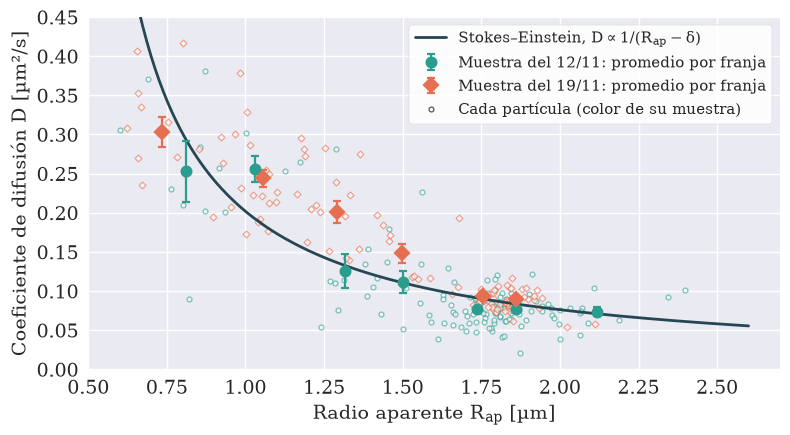

In [8]:
BORDES_R = np.array([0.6, 0.9, 1.2, 1.4, 1.6, 1.8, 2.0, 2.5])       # franjas de 0.2 a 0.5 µm


def franjas(s):
    fr = s.groupby(pd.cut(s.R_ap_um, BORDES_R), observed=True).agg(n=("D_um2_s", "size"), R=("R_ap_um", "mean"), D=("D_um2_s", "mean"), sd=("D_um2_s", "std"))
    fr = fr[fr.n >= 4].copy()
    fr["err"] = fr.sd / np.sqrt(fr.n)
    return fr.reset_index(drop=True)


FR = {m: franjas(libres[libres.muestra == m]) for m in muestras_dia}
conjuntos = dict(FR)
if len(FR) > 1:
    conjuntos["las %d juntas" % len(FR)] = pd.concat(FR.values(), ignore_index=True)
modelos = {"1/R": (lambda R, A: A / R, [0.14]),
           "exponente libre": (lambda R, A, p: A / R ** p, [0.14, 1.0]),
           "radio corrido": (lambda R, A, d: A / (R - d), [0.12, 0.3])}
ajustes, filas = {}, []
for nombre_c, fr in conjuntos.items():
    for nombre_m, (f, p0) in modelos.items():
        p, cov = optimize.curve_fit(f, fr.R.values, fr.D.values, p0=p0, sigma=fr.err.values, absolute_sigma=False)
        chi2 = float(np.sum(((fr.D.values - f(fr.R.values, *p)) / fr.err.values) ** 2))
        gl = len(fr) - len(p)
        ajustes[(nombre_c, nombre_m)] = (f, p, np.sqrt(np.diag(cov)))
        filas.append({"muestra": nombre_c, "curva": nombre_m, "A [µm³/s]": p[0], "± A": np.sqrt(cov[0, 0]),
                      "p o δ [µm]": p[1] if len(p) > 1 else np.nan, "± p o δ": np.sqrt(cov[1, 1]) if len(p) > 1 else np.nan,
                      "chi2 por grado": chi2 / gl, "grados de libertad": gl, "viscosidad que sale de A [mPa·s]": 1e3 * KT / (6 * np.pi * p[0] * 1e-18)})
tabla_ajustes = pd.DataFrame(filas)
csv(tabla_ajustes, "todas_D_vs_radio_ajustes.csv")
csv(pd.concat([fr.assign(muestra=m) for m, fr in FR.items()]).rename(columns={"n": "particulas", "R": "R_ap_um", "D": "D_um2_s", "sd": "dispersion_um2_s", "err": "err_D_um2_s"})[
    ["muestra", "particulas", "R_ap_um", "D_um2_s", "dispersion_um2_s", "err_D_um2_s"]], "todas_D_vs_radio_franjas.csv")

ultimo = list(conjuntos)[-1]
f, p, ep = ajustes[(ultimo, "radio corrido")]
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in muestras_dia:
    q = libres[libres.muestra == m]
    color, marca, etiqueta = ESTILO[m]
    ax.plot(q.R_ap_um, q.D_um2_s, marca, ms=3.5, color=color, mfc="white", mec=color, mew=0.9, alpha=0.6, zorder=2)
    ax.errorbar(FR[m].R, FR[m].D, FR[m].err, fmt=marca, color=color, mfc=color, mec=color, label=etiqueta + ": promedio por franja", **{**MARCA, "zorder": 4})
rr = np.linspace(0.62, 2.6, 300)
ax.plot(rr, f(rr, *p), color=AJUSTE, lw=2, zorder=3, label=r"Stokes–Einstein, $D \propto 1/(R_{ap} - \delta)$")
manijas, textos = ax.get_legend_handles_labels()
manijas.append(Line2D([], [], ls="", marker="o", ms=3.5, mfc="white", mec="#555555", mew=0.9)); textos.append("Cada partícula (color de su muestra)")
ax.set_xlabel(r"Radio aparente $R_{ap}$ [µm]"); ax.set_ylabel(r"Coeficiente de difusión $D$ [µm²/s]")
ax.set_xlim(0.5, 2.7); ax.set_ylim(0, 0.45)
ax.legend(manijas, textos, loc="upper right", fontsize=11, **LEYENDA)
guardar(fig, "D_vs_radio")
print("curva de la figura (%s): borde δ = %.2f ± %.2f µm → una partícula de %.1f µm de radio real se ve de %.2f ± %.2f µm"
      % (ultimo, p[1], ep[1], R_NOMINAL, R_NOMINAL + p[1], ep[1]))
print("   viscosidad que sale de su constante: %.2f ± %.2f mPa·s" % (1e3 * KT / (6 * np.pi * p[0] * 1e-18), 1e3 * KT / (6 * np.pi * p[0] * 1e-18) * ep[0] / p[0]))
for m in muestras_dia:
    q = libres[libres.muestra == m]
    print("muestra %s: de las %d libres con D > 0.15 µm²/s, %d tienen R_ap < %.1f µm; de las %d con D < 0.12, %d tienen R_ap ≥ %.1f µm"
          % (m, (q.D_um2_s > 0.15).sum(), ((q.D_um2_s > 0.15) & (q.R_ap_um < BORDES_CLASE[1])).sum(), BORDES_CLASE[1],
             (q.D_um2_s < 0.12).sum(), ((q.D_um2_s < 0.12) & (q.R_ap_um >= BORDES_CLASE[1])).sum(), BORDES_CLASE[1]))
for m, fr in FR.items():
    print("franjas, muestra %s:" % m); print(fr.round(4).to_string(index=False))
tabla_ajustes.round(3)

**Qué se ve.**

- **$D$ baja con el radio aparente en las dos muestras**, de 0.25 a 0.30 µm²/s en las más chicas a 0.07 a 0.09 en las nominales. **Las que difunden rápido son las de radio aparente chico**: de las libres con $D$ > 0.15 µm²/s, tienen $R_{ap}$ < 1.6 µm las 16 del 12/11 y 50 de las 51 del 19/11. Al revés, de las que tienen $D$ < 0.12, tienen $R_{ap}$ ≥ 1.6 µm 103 de 119 y 52 de 56. Los dos grupos de $D$ que se veían el 19/11 antes de tener los radios son eso: nominales y chicas.
- **Con el radio aparente tal cual, los datos no siguen $1/R$.** Esa curva queda muy por debajo de las chicas: $\chi^2$ por grado de libertad de 10 a 19. Con el exponente libre sale $D \propto R_{ap}^{-1.8 \pm 0.2}$ el 12/11 y $R_{ap}^{-1.5 \pm 0.2}$ el 19/11: más empinado que $1/R$.
- **Con el radio corrido, Stokes–Einstein describe la tendencia** (la curva de la figura). El borde que sale es $\delta$ = 0.51 ± 0.10 µm el 12/11, 0.32 ± 0.11 µm el 19/11 y **0.39 ± 0.08 µm con las dos juntas**: unos 0.4 µm, parecido los dos días.
- **Qué quiere decir ese borde.** Una partícula de radio real 1.5 µm se tiene que ver de 1.5 + 0.4 = 1.9 µm (1.89 ± 0.08). Y el pico del histograma está en 1.8 a 1.9 µm. Es decir: lo que acá se llama **«nominal» (radio aparente de 1.6 a 2.1 µm, con el pico en 1.8 a 1.9) son las partículas de 1.5 µm de radio nominal**, y las dos cosas cierran. Con la misma cuenta, las chicas de 0.9 a 1.0 µm de radio aparente tendrían unos 0.5 µm de radio real: lo mismo que da su radio equivalente (sección 6).
- **No es una demostración.** La curva tampoco pasa por todos los puntos dentro de sus errores ($\chi^2$ por grado de libertad de 6 a 12) y no ajusta mejor que el exponente libre. Tres razones por las que no puede ajustar fino: el radio aparente de cada partícula baila 0.2 µm con el foco; entre 1.2 y 1.6 µm las del 19/11 difunden más que las del 12/11 (ahí la mezcla de tamaños no es la misma los dos días); y no se sabe a qué altura está cada una (si las chicas flotan más lejos del vidrio, la pared las frena menos y difunden de más). Haría falta saber qué tamaños nominales se mezclaron.
- La viscosidad que sale de la constante $A$ depende de qué radio se use (1.0 a 2.1 mPa·s según la curva), así que acá no se informa como resultado. La viscosidad efectiva va en la sección 9, con las partículas nominales, que son las únicas con radio conocido.
- En la figura, los puntos chicos huecos son las partículas una por una (sin barra de error, para que se vea) y los puntos grandes con barra son los promedios por franja de cada muestra.

## 8. ¿Es browniano?

Cinco chequeos, para cada muestra y cada clase con al menos 5 partículas libres:

1. **Forma de campana.** Se juntan los pasos de un cuadro de todas las partículas, cada uno dividido por el desvío estándar de los pasos de su partícula (así se pueden juntar partículas con $D$ distinto). Para un browniano el histograma es una gaussiana. La **curtosis** mide si hay más pasos grandes que en una gaussiana: 0 = gaussiana, positiva = sobran pasos grandes. Se calcula de dos formas: dividiendo por el desvío de toda la trayectoria, y dividiendo por el desvío de cada trozo de 6 s. La segunda dice si los pasos son gaussianos «en cada momento»; se compara con lo que da una gaussiana pura con la misma cuenta (un poco menos que 0, porque el desvío de cada trozo se estima con pocos pasos).
2. **Crece en línea recta.** El MSD (acá, la varianza del desplazamiento en 2D, sin el arrastre) promediado entre partículas, contra el retardo. Para un browniano es una recta; en escala log-log, pendiente $\alpha$ = 1. El error de localización la baja un poco: se compara con el $\alpha$ de la recta ajustada (que tiene ordenada).
3. **Pasos independientes.** La correlación entre un paso y el siguiente (entre −1 y 1; 0 = no tienen que ver). Para un browniano medido con error no da exactamente 0: dos pasos seguidos comparten la posición del medio, y si esa se midió corrida, un paso sale de más y el otro de menos. Por eso se compara con la correlación **esperada por el error de localización** de cada partícula (sale de la ordenada de su recta).
4. **Igual en $x$ y en $y$.** El cociente $D_y / D_x$ tiene que dar 1.
5. **No se mueven juntas.** La correlación entre los pasos simultáneos de dos partículas distintas. Si la imagen entera temblara (platina, mesa), todas se moverían a la vez y daría mayor que 0. Se calcula por grabación, con todas sus libres.

Las figuras (histograma de pasos y MSD promedio) se hacen una por muestra.

MSD promedio, muestra 12/11, nominal: pendiente / 4 = 0.0773 µm²/s, ordenada 0.0059 µm² (error de localización 38 nm por eje)
MSD promedio, muestra 12/11, intermedia: pendiente / 4 = 0.1150 µm²/s, ordenada 0.0090 µm² (error de localización 47 nm por eje)
MSD promedio, muestra 12/11, chica: pendiente / 4 = 0.2697 µm²/s, ordenada -0.0115 µm² (negativa: pesa más la exposición de la cámara que el error de localización)


MSD promedio, muestra 19/11, nominal: pendiente / 4 = 0.0911 µm²/s, ordenada 0.0052 µm² (error de localización 36 nm por eje)
MSD promedio, muestra 19/11, intermedia: pendiente / 4 = 0.1760 µm²/s, ordenada 0.0131 µm² (error de localización 57 nm por eje)
MSD promedio, muestra 19/11, chica: pendiente / 4 = 0.2518 µm²/s, ordenada 0.0173 µm² (error de localización 66 nm por eje)


correlación entre partículas distintas, todas las grabaciones: +0.002 (1 cuadro), +0.003 (4 cuadros); la mayor de una grabación: 0.010 y 0.016


,muestra,clase,partículas,pasos,curtosis,± curtosis,pasos de más de 3 desvíos [%],curtosis por trozo de 6 s,la de una gaussiana pura,alfa del MSD promedio,alfa de la recta ajustada,ordenada del MSD [µm²],correlación entre pasos seguidos,± correlación,esperada por el error de localización,Dy / Dx,± Dy / Dx
0,12/11,nominal,102,134844,0.481,0.013,0.521,-0.044,-0.057,0.971,0.971,0.006,-0.099,0.003,-0.086,1.001,0.024
1,12/11,intermedia,22,15514,0.247,0.039,0.419,-0.038,-0.068,0.973,0.970,0.009,-0.034,0.008,-0.013,0.944,0.058
2,12/11,chica,13,7754,0.083,0.056,0.284,-0.078,-0.025,1.022,1.017,-0.011,-0.029,0.012,-0.001,1.079,0.087
3,19/11,nominal,52,152432,0.349,0.013,0.435,-0.008,-0.047,0.979,0.978,0.005,-0.066,0.003,-0.057,0.935,0.025
4,19/11,intermedia,20,31516,0.219,0.028,0.368,-0.046,-0.048,0.974,0.971,0.013,-0.032,0.006,-0.025,0.900,0.040
5,19/11,chica,36,35094,0.123,0.026,0.339,-0.049,-0.052,0.967,0.973,0.017,-0.024,0.005,-0.012,0.996,0.048


,grabación,libres,pares de pasos simultáneos,correlación entre partículas (1 cuadro),± (1 cuadro),correlación entre partículas (4 cuadros),± (4 cuadros)
0,BROWNIANO 1,4,9226,0.009,0.010,0.013,0.021
1,BROWNIANO 2,19,68894,0.005,0.004,0.003,0.008
2,BARRIDO 1,21,19190,-0.008,0.007,-0.011,0.015
3,LASER 5,13,78890,-0.001,0.004,-0.010,0.007
4,BARRIDO POTENCIAS 2,11,86008,0.004,0.003,0.006,0.007
5,BARRIDO STEPSIZE,21,26868,0.006,0.006,0.006,0.012
6,BARRIDO STEPSIZE 2,29,30470,0.006,0.006,0.016,0.012
7,BARRIDO STEPSIZE 3,27,28954,-0.010,0.006,0.005,0.012
8,BARRIDO POTENCIAS 3,18,109330,0.006,0.003,-0.002,0.006
9,BARRIDO POTENCIAS 4,19,140264,0.003,0.003,0.005,0.005


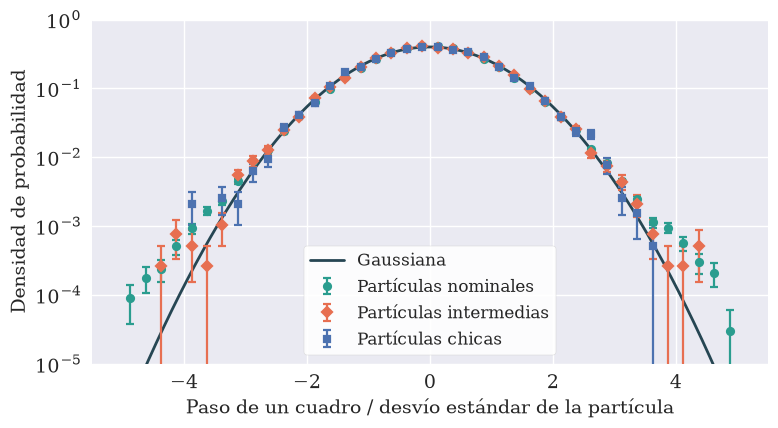

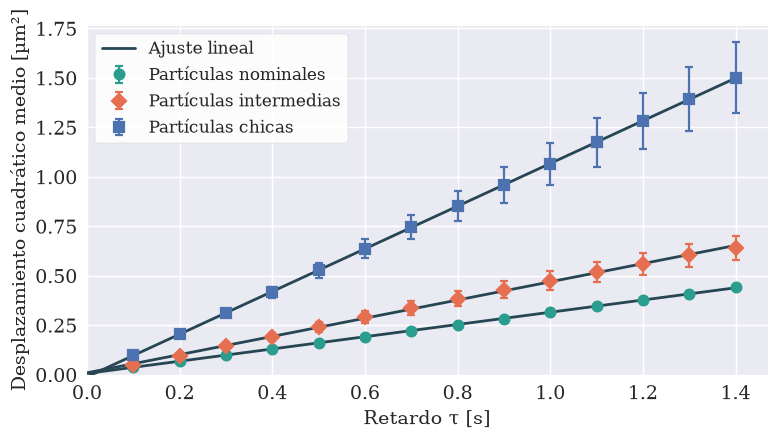

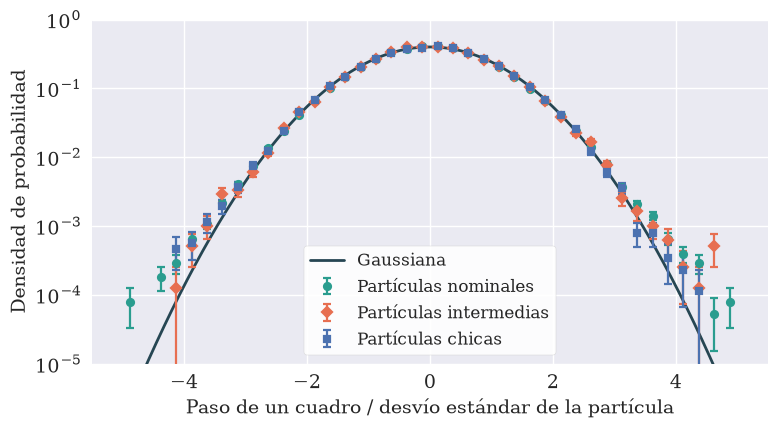

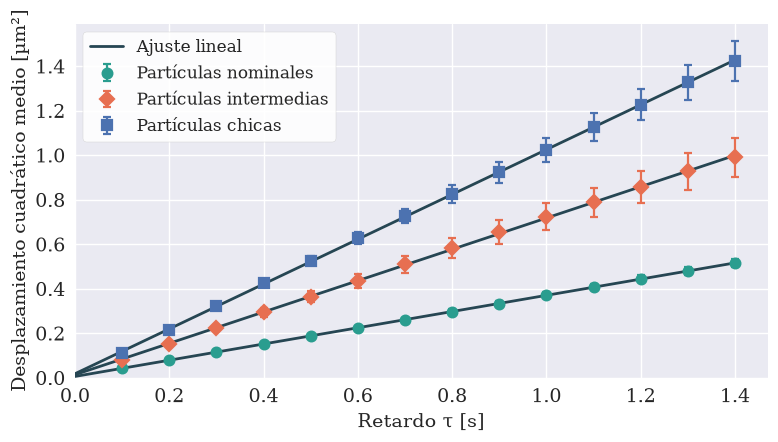

In [9]:
TAU = np.arange(1, 15) * 0.1          # retardos comunes [s] (cada grabación tiene su período; se interpola)


def chequear(s):
    # Junta los pasos y el MSD de las partículas de la tabla s (una clase de una muestra)
    z, zt, zt_ref, a, b, r_esp, peso, V = [], [], [], [], [], [], [], []
    azar = np.random.default_rng(1)
    for nombre, sg in s.groupby("grabacion", sort=False):
        g = GRAB[nombre]
        for (_, f), uno in zip(sg.iterrows(), bt.pasos(g, sg.particula.values)):
            for eje in "xy":
                d = uno["d" + eje]
                if len(d) < 50:
                    continue
                z.append(d / d.std())
                a.append(uno["par_" + eje][0] / d.std()); b.append(uno["par_" + eje][1] / d.std())
                zt.append(uno["zt_" + eje])
                for n_trozo in uno["nt_" + eje]:                      # la misma cuenta con una gaussiana pura
                    r = azar.standard_normal(int(n_trozo))
                    zt_ref.append((r - r.mean()) / r.std(ddof=1))
            v1 = 2 * f.D_um2_s * g["dt"] + f.ordenada_um2            # varianza de un paso según la recta
            r_esp.append(-0.5 * f.ordenada_um2 / v1); peso.append(f.cuadros)
        tau, Vg = bt.juntar_msd(g, sg.particula.values)
        V += [np.interp(TAU, tau, Vg[:, j]) for j in range(Vg.shape[1]) if np.all(np.isfinite(Vg[:, j]))]
    z, zt, zt_ref, a, b, V = np.concatenate(z), np.concatenate(zt), np.concatenate(zt_ref), np.concatenate(a), np.concatenate(b), np.array(V).T
    msd, err_msd = V.mean(1), V.std(1, ddof=1) / np.sqrt(V.shape[1])
    recta = np.polyfit(TAU, msd, 1)
    lejos = TAU >= 0.3
    dif = (s.Dy_um2_s - s.Dx_um2_s).values
    return dict(z=z, msd=msd, err_msd=err_msd, recta=recta,
                fila={"partículas": len(s), "pasos": len(z), "curtosis": stats.kurtosis(z), "± curtosis": np.sqrt(24 / len(z)),
                      "pasos de más de 3 desvíos [%]": 100 * np.mean(np.abs(z) > 3),
                      "curtosis por trozo de 6 s": stats.kurtosis(zt), "la de una gaussiana pura": stats.kurtosis(zt_ref),
                      "alfa del MSD promedio": np.polyfit(np.log(TAU[lejos]), np.log(msd[lejos]), 1)[0],
                      "alfa de la recta ajustada": np.polyfit(np.log(TAU[lejos]), np.log(np.polyval(recta, TAU[lejos])), 1)[0],
                      "ordenada del MSD [µm²]": recta[1],
                      "correlación entre pasos seguidos": np.corrcoef(a, b)[0, 1], "± correlación": 1 / np.sqrt(len(a)),
                      "esperada por el error de localización": np.average(r_esp, weights=peso),
                      "Dy / Dx": s.Dy_um2_s.mean() / s.Dx_um2_s.mean(), "± Dy / Dx": dif.std(ddof=1) / np.sqrt(len(s)) / s.Dx_um2_s.mean()})


CHEQ, filas = {}, []
for m in muestras:
    for clase in ESTILO_CLASE:
        s = libres[(libres.muestra == m) & (libres.clase == clase)]
        if len(s) >= 5:
            CHEQ[(m, clase)] = chequear(s)
            filas.append({"muestra": m, "clase": clase, **CHEQ[(m, clase)]["fila"]})
tabla_cheq = pd.DataFrame(filas)
csv(tabla_cheq, "todas_chequeos_browniano.csv")

ancho = 0.25
bz = np.arange(-5, 5 + ancho / 2, ancho)
cz = 0.5 * (bz[1:] + bz[:-1])
u = np.linspace(-5, 5, 400)
hist_csv, msd_csv = [], []
for m in [m for m in muestras if any(k[0] == m for k in CHEQ)]:
    # --- histograma de pasos de esta muestra, por clase
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for clase, (color, marca, etiqueta) in ESTILO_CLASE.items():
        if (m, clase) not in CHEQ:
            continue
        z = CHEQ[(m, clase)]["z"]
        n, _ = np.histogram(z, bz)
        hay = n > 0
        ax.errorbar(cz[hay], n[hay] / (len(z) * ancho), np.sqrt(n[hay]) / (len(z) * ancho), fmt=marca, color=color, mfc=color, mec=color,
                    label=etiqueta, **{**MARCA, "ms": 5})
        hist_csv.append(pd.DataFrame({"muestra": m, "clase": clase, "paso_sobre_desvio": cz, "pasos": n, "densidad": n / (len(z) * ancho),
                                      "gaussiana": np.exp(-cz ** 2 / 2) / np.sqrt(2 * np.pi)}))
    ax.plot(u, np.exp(-u ** 2 / 2) / np.sqrt(2 * np.pi), color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
    ax.set_yscale("log"); ax.set_ylim(1e-5, 1)
    ax.set_xlabel("Paso de un cuadro / desvío estándar de la partícula"); ax.set_ylabel("Densidad de probabilidad")
    ax.legend(loc="lower center", fontsize=12, **LEYENDA)
    guardar(fig, "histograma_pasos_" + archivo(m))

    # --- MSD promedio de esta muestra, por clase
    fig, ax = plt.subplots(figsize=(8, 4.5))
    primera = True
    for clase, (color, marca, etiqueta) in ESTILO_CLASE.items():
        if (m, clase) not in CHEQ:
            continue
        c = CHEQ[(m, clase)]
        ax.errorbar(TAU, c["msd"], c["err_msd"], fmt=marca, color=color, mfc=color, mec=color, label=etiqueta, **MARCA)
        ax.plot(np.r_[0, TAU], np.polyval(c["recta"], np.r_[0, TAU]), color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal" if primera else None)
        primera = False
        msd_csv.append(pd.DataFrame({"muestra": m, "clase": clase, "retardo_s": TAU, "msd_um2": c["msd"], "err_msd_um2": c["err_msd"]}))
        print("MSD promedio, muestra %s, %s: pendiente / 4 = %.4f µm²/s, ordenada %.4f µm² (%s)" % (m, clase, c["recta"][0] / 4, c["recta"][1],
              "error de localización %.0f nm por eje" % (1e3 * np.sqrt(c["recta"][1] / 4)) if c["recta"][1] > 0 else "negativa: pesa más la exposición de la cámara que el error de localización"))
    ax.set_xlabel(r"Retardo $\tau$ [s]"); ax.set_ylabel("Desplazamiento cuadrático medio [µm²]")
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.legend(loc="upper left", fontsize=12, **LEYENDA)
    guardar(fig, "msd_promedio_" + archivo(m))
csv(pd.concat(hist_csv, ignore_index=True), "todas_histograma_pasos.csv")
csv(pd.concat(msd_csv, ignore_index=True), "todas_msd_promedio.csv")

# --- ¿se mueven juntas? por grabación, con todas sus libres
filas = []
for nombre in GRAB:
    ids = libres.particula[libres.grabacion == nombre].values
    if len(ids) >= 2:
        r1, e1, n1 = bt.movimiento_comun(GRAB[nombre], ids, lag=1)
        r4, e4, _ = bt.movimiento_comun(GRAB[nombre], ids, lag=4)
        filas.append({"grabación": nombre, "libres": len(ids), "pares de pasos simultáneos": n1, "correlación entre partículas (1 cuadro)": r1, "± (1 cuadro)": e1,
                      "correlación entre partículas (4 cuadros)": r4, "± (4 cuadros)": e4})
tabla_comun = pd.DataFrame(filas)
csv(tabla_comun, "todas_movimiento_comun.csv")
peso = tabla_comun["pares de pasos simultáneos"]
print("correlación entre partículas distintas, todas las grabaciones: %+.3f (1 cuadro), %+.3f (4 cuadros); la mayor de una grabación: %.3f y %.3f"
      % (np.average(tabla_comun["correlación entre partículas (1 cuadro)"], weights=peso), np.average(tabla_comun["correlación entre partículas (4 cuadros)"], weights=peso),
         tabla_comun["correlación entre partículas (1 cuadro)"].abs().max(), tabla_comun["correlación entre partículas (4 cuadros)"].abs().max()))
display(tabla_cheq.round(3))
tabla_comun.round(3)

**Qué se ve.** Entran 158 000 pasos de un cuadro del 12/11 y 219 000 del 19/11 (contando $x$ e $y$).

1. **Campana: casi, los dos días.** El histograma sigue a la gaussiana en el centro, pero sobran pasos grandes: en las nominales pasa de 3 desvíos el 0.52 % de los pasos el 12/11 y el 0.44 % el 19/11, contra 0.27 % de una gaussiana (curtosis 0.48 y 0.35; en las intermedias y las chicas, 0.1 a 0.25). Dividiendo por el desvío de cada trozo de 6 s, en cambio, la curtosis da lo mismo que una gaussiana pura (en las nominales −0.04 contra −0.06 el 12/11 y −0.01 contra −0.05 el 19/11). O sea: **en cada momento los pasos son gaussianos; lo que cambia despacio es su ancho.** Es lo que pasa si la partícula sube y baja: cambia el foco (y con él el error de localización) y cambia el frenado de la pared.
2. **Recta: sí.** El MSD promedio es una recta en todo el rango (0.1 a 1.4 s) en las tres clases y los dos días. $\alpha$ da 0.97 a 1.02, igual que el de la recta ajustada: lo poco que le falta para 1 es la ordenada, que es el error de localización (38 nm en las nominales del 12/11 y 36 nm en las del 19/11).
3. **Independientes: sí, dentro de 0.03.** La correlación entre pasos seguidos de las nominales es −0.10 el 12/11 y −0.07 el 19/11, y por el error de localización se esperaba −0.09 y −0.06. Queda −0.01 a −0.03 sin explicar según la clase.
4. **Igual en $x$ y en $y$: sí el 12/11; el 19/11, casi.** El 12/11 $D_y / D_x$ = 1.00 ± 0.02 en las nominales. El 19/11 da 0.93 ± 0.03 en las nominales y 0.90 ± 0.04 en las intermedias (2.5 errores por debajo de 1) y 1.00 ± 0.05 en las chicas; con todas las libres del día juntas, 0.96 ± 0.03. No alcanza para decir que haya una diferencia real entre ejes, pero conviene mirarlo si se graba de nuevo.
5. **No se mueven juntas.** La correlación entre partículas distintas es +0.002 en promedio y no pasa de 0.010 en ninguna grabación (0.016 a 4 cuadros): menos del 1 % de la varianza de los pasos es movimiento común. La imagen no tiembla, ni el 12/11 ni el 19/11.

**Las partículas libres se mueven como un browniano los dos días**, con la salvedad del punto 1.

## 9. Arrastre y viscosidad por día, y comparación con lo que ya había

Con el $D$ de las partículas nominales (las únicas con radio conocido: 1.5 µm) de cada muestra:

- **Coeficiente de arrastre** $\gamma = k_BT / D$ (Einstein). No supone radio ni viscosidad.
- **Viscosidad efectiva** $\eta = k_BT / (6\pi R D)$ (Stokes–Einstein) con el radio nominal. «Efectiva» porque incluye el frenado de la pared si las partículas están cerca del vidrio.
- **Qué mezcla de glicerina y agua** tiene esa viscosidad (`fisica.viscosidad_glicerina_agua`), a 23 °C y en los extremos 20 y 26 °C.

Como error de $D$ se toma el mayor entre el estadístico y la dispersión entre grabaciones dividida por $\sqrt{\text{grabaciones}}$. La temperatura (23 ± 3 °C, supuesta) entra con 1 % en $\gamma$ y en $\eta$.

**La que estaba atrapada.** En los barridos de potencia el láser se apaga al final y la partícula que estaba en la trampa queda libre. Se mide su $D$ con los cuadros de 3 s después del apagado en adelante (los tiempos salen de `datos/cuaderno/potencias_cuaderno.csv`). Es la misma partícula a la que después se le calcula la fuerza de la trampa, así que su arrastre es el que más importa.

In [10]:
def glicerina_para(eta, T):
    # Fracción en masa de glicerina que da esa viscosidad [Pa·s] a la temperatura T [K]
    f = lambda c: float(fisica.viscosidad_glicerina_agua(c, T)) - eta
    return optimize.brentq(f, 0.0, 0.99) if f(0.0) < 0 else 0.0


def derivados(D, eD):
    gamma = KT / (D * 1e-12)
    eta = gamma / (6 * np.pi * R_NOMINAL * 1e-6)
    return {"D [µm²/s]": D, "± D": eD, "gamma [1e-8 N·s/m]": gamma * 1e8, "± gamma": gamma * 1e8 * np.hypot(eD / D, ERR_T / T_AMB),
            "viscosidad efectiva [mPa·s]": eta * 1e3, "± viscosidad": eta * 1e3 * np.hypot(eD / D, ERR_T / T_AMB),
            "glicerina a 23 °C [% en masa]": 100 * glicerina_para(eta, T_AMB),
            "a 20 °C": 100 * glicerina_para(eta * (T_AMB - ERR_T) / T_AMB, T_AMB - ERR_T), "a 26 °C": 100 * glicerina_para(eta * (T_AMB + ERR_T) / T_AMB, T_AMB + ERR_T)}


nominales = libres[libres.clase == "nominal"]
filas = []
for m in muestras_dia:
    D, eD, n = D_de(nominales[nominales.muestra == m])
    filas.append({"qué": "ESTE ANÁLISIS: nominales, muestra %s" % m, "partículas": n, **derivados(D, eD)})
juntas = compat[compat["qué se compara"] == "nominal, solo barridos de potencia"] if len(compat) else compat
if len(juntas) and np.isfinite(juntas["D las dos juntas"].iloc[0]):          # solo si salieron compatibles (sección 6)
    filas.append({"qué": "ESTE ANÁLISIS: nominales de los barridos de potencia, los dos días juntos",
                  "partículas": int(juntas.iloc[0, 1] + juntas.iloc[0, 4]), **derivados(juntas["D las dos juntas"].iloc[0], juntas["± juntas"].iloc[0])})

# la que estaba atrapada, una vez apagado el láser
sueltas = pd.concat([bt.soltadas(g, largo_min=LARGO_MIN) for g in GRAB.values() if g["usar"]], ignore_index=True)
csv(sueltas, "todas_atrapada_suelta.csv")
for m, s in sueltas.groupby("muestra", sort=False):
    if len(s) > 1:
        filas.append({"qué": "este análisis: la atrapada, ya suelta, muestra %s" % m, "partículas": len(s),
                      **derivados(s.D_um2_s.mean(), s.D_um2_s.std(ddof=1) / np.sqrt(len(s)))})

for etiqueta, nombres in (("este análisis: nominales de BROWNIANO 2", ["BROWNIANO 2"]),
                          ("este análisis: nominales de LASER 5 y BARRIDO POTENCIAS 2", ["LASER 5", "BARRIDO POTENCIAS 2"]),
                          ("este análisis: nominales de las grabaciones con patadas", [n for n in GRAB if CATALOGO.get(n, {}).get("tipo") == "patadas"]),
                          ("este análisis: nominales de BROWNIANO 1 (otra muestra)", ["BROWNIANO 1"])):
    sel = nominales[nominales.grabacion.isin(nombres)]
    if len(sel) > 1:
        D, eD, n = D_de(sel)
        filas.append({"qué": etiqueta, "partículas": n, **derivados(D, eD)})
# lo que ya había (valores de los análisis anteriores)
for etiqueta, n, D, eD in (("antes: BROWNIANO 2, beads solas (comparación de mediciones)", 7, 0.079, 0.007),
                           ("antes: libres de LASER 5 y BARRIDO POTENCIAS 2 (fuerza y pozo)", 22, 0.082, 0.004),
                           ("antes: BROWNIANO 1, beads solas (comparación de mediciones)", 3, 0.056, 0.004)):
    filas.append({"qué": etiqueta, "partículas": n, **derivados(D, eD)})
comparacion = pd.DataFrame(filas)
csv(comparacion, "todas_comparacion.csv")

masa_g, masa_a = 65 * 1.261, 60 * 0.9975                     # receta del cuaderno: 65 ml de glicerina + 60 ml de agua
eta_receta = float(fisica.viscosidad_glicerina_agua(masa_g / (masa_g + masa_a), T_AMB))
D_receta = KT / (6 * np.pi * eta_receta * R_NOMINAL * 1e-6) * 1e12
eta_agua = float(fisica.viscosidad_glicerina_agua(0.0, T_AMB))
print("receta del cuaderno del 12/11 (65 ml de glicerina + 60 ml de agua = %.0f %% en masa): %.1f mPa·s → D esperado %.3f µm²/s para R = 1.5 µm"
      % (100 * masa_g / (masa_g + masa_a), eta_receta * 1e3, D_receta))
for _, f in comparacion.iloc[:len(muestras_dia)].iterrows():
    print("   %s: D medido / D de la receta = %.1f" % (f["qué"], f["D [µm²/s]"] / D_receta))
for m, s in sueltas.groupby("muestra", sort=False):
    D_l, e_l, _ = D_de(nominales[nominales.muestra == m])
    D_s, e_s = s.D_um2_s.mean(), s.D_um2_s.std(ddof=1) / np.sqrt(len(s))
    print("la atrapada ya suelta, muestra %s: D = %.4f ± %.4f µm²/s (%d trayectorias) contra %.4f ± %.4f de las libres nominales: cociente %.2f, %.1f errores"
          % (m, D_s, e_s, len(s), D_l, e_l, D_s / D_l, (D_s - D_l) / np.hypot(e_s, e_l)))
print("agua pura a 23 °C: %.2f mPa·s → D = %.3f µm²/s" % (1e3 * eta_agua, KT / (6 * np.pi * eta_agua * R_NOMINAL * 1e-6) * 1e12))
display(sueltas.round(4))
comparacion.round(3)

receta del cuaderno del 12/11 (65 ml de glicerina + 60 ml de agua = 58 % en masa): 8.4 mPa·s → D esperado 0.017 µm²/s para R = 1.5 µm
   ESTE ANÁLISIS: nominales, muestra 12/11: D medido / D de la receta = 4.4
   ESTE ANÁLISIS: nominales, muestra 19/11: D medido / D de la receta = 5.2
la atrapada ya suelta, muestra 19/11: D = 0.0789 ± 0.0038 µm²/s (5 trayectorias) contra 0.0906 ± 0.0039 de las libres nominales: cociente 0.87, -2.2 errores
agua pura a 23 °C: 0.94 mPa·s → D = 0.155 µm²/s


,grabacion,muestra,particula,cuadros,D_um2_s,err_D_um2_s,alfa
0,BARRIDO POTENCIAS 3,19/11,0,730,0.070966,0.004512,0.908318
1,BARRIDO POTENCIAS 4,19/11,0,750,0.085815,0.008815,1.062151
2,BARRIDO POTENCIAS 6,19/11,0,536,0.06833,0.005796,0.923771
3,BARRIDO POTENCIAS 7,19/11,0,591,0.084483,0.005875,1.083513
4,BARRIDO POTENCIAS 8,19/11,1,805,0.084929,0.009028,1.125902


,qué,partículas,D [µm²/s],± D,gamma [1e-8 N·s/m],± gamma,viscosidad efectiva [mPa·s],± viscosidad,glicerina a 23 °C [% en masa],a 20 °C,a 26 °C
0,"ESTE ANÁLISIS: nominales, muestra 12/11",102,0.076,0.003,5.413,0.246,1.915,0.087,25.422,22.615,28.120
1,"ESTE ANÁLISIS: nominales, muestra 19/11",52,0.091,0.004,4.515,0.197,1.597,0.070,19.816,16.872,22.635
2,ESTE ANÁLISIS: nominales de los barridos de po...,70,0.089,0.003,4.574,0.170,1.618,0.060,20.233,17.300,23.043
3,"este análisis: la atrapada, ya suelta, muestra...",5,0.079,0.004,5.182,0.256,1.833,0.090,24.117,21.279,26.842
4,este análisis: nominales de BROWNIANO 2,7,0.077,0.005,5.298,0.344,1.874,0.122,24.781,21.959,27.492
5,este análisis: nominales de LASER 5 y BARRIDO ...,18,0.086,0.004,4.753,0.225,1.681,0.079,21.453,18.550,24.236
6,este análisis: nominales de las grabaciones co...,77,0.073,0.004,5.606,0.348,1.983,0.123,26.452,23.668,29.127
7,este análisis: nominales de BROWNIANO 1 (otra ...,3,0.055,0.002,7.413,0.329,2.622,0.117,34.090,31.475,36.613
8,"antes: BROWNIANO 2, beads solas (comparación d...",7,0.079,0.007,5.176,0.462,1.831,0.163,24.080,21.241,26.806
9,antes: libres de LASER 5 y BARRIDO POTENCIAS 2...,22,0.082,0.004,4.986,0.248,1.764,0.088,22.944,20.078,25.694


**Qué se ve.**

| Nominales de | $D$ [µm²/s] | $\gamma$ [10⁻⁸ N·s/m] | Viscosidad efectiva [mPa·s] | Glicerina que la daría |
|---|---|---|---|---|
| 12/11, todas las grabaciones | 0.076 ± 0.003 | 5.4 ± 0.2 | 1.91 ± 0.09 | 25 % (23 a 28) |
| 19/11 (todas son barridos de potencia) | 0.091 ± 0.004 | 4.5 ± 0.2 | 1.60 ± 0.07 | 20 % (17 a 23) |
| 12/11, solo barridos de potencia | 0.086 ± 0.004 | 4.8 ± 0.2 | 1.68 ± 0.08 | 21 % |
| 12/11, solo grabaciones con patadas | 0.073 ± 0.005 | 5.6 ± 0.3 | 1.98 ± 0.12 | 26 % |
| barridos de potencia, los dos días juntos | 0.089 ± 0.003 | 4.6 ± 0.2 | 1.62 ± 0.06 | 20 % |

- **Por día:** el arrastre de una partícula nominal es (5.4 ± 0.2) × 10⁻⁸ N·s/m el 12/11 y (4.5 ± 0.2) × 10⁻⁸ el 19/11. La diferencia viene de las grabaciones con patadas del 12/11; en los barridos de potencia los dos días coinciden (sección 6).
- **La viscosidad efectiva es 1.6 a 1.9 mPa·s**, alrededor del doble que el agua (0.94): la de una mezcla con 20 a 25 % de glicerina en masa. La receta anotada el 12/11 (58 %) daría 8.4 mPa·s y una difusión 4 a 5 veces más lenta: sigue sin cerrar. Si las partículas están cerca del vidrio, parte de esa viscosidad «efectiva» es frenado de la pared y la mezcla tendría menos glicerina.
- **La que estaba atrapada, ya suelta** (19/11, cinco trayectorias; las de las grabaciones 4 y 6 son la misma partícula, y en la 7 lleva una chica pegada): $D$ = 0.079 ± 0.004 µm²/s, o sea $\gamma$ = (5.2 ± 0.3) × 10⁻⁸ N·s/m. Difunde 13 % menos que las libres nominales del mismo día (2.2 errores). Coincide con lo que había dado la atrapada casi suelta del 12/11 en el análisis de patadas (0.074 µm²/s). Puede ser que la trampa la deje más cerca del vidrio que a las libres.
- **Coincide con lo anterior donde se puede comparar.** Con las mismas grabaciones, este método da 0.077 ± 0.005 µm²/s en `BROWNIANO 2` (antes 0.079 ± 0.007), 0.086 ± 0.004 en `LASER 5` y `BARRIDO POTENCIAS 2` (antes 0.082 ± 0.004) y 0.055 ± 0.002 en `BROWNIANO 1` (antes 0.056 ± 0.004). El método es otro (varianza por trozos en vez de restar una recta) y ahora se sacaron los agregados.
- **Para el análisis de patadas:** el $\gamma$ que se usó ahí para pasar a pN, (5.0 ± 0.2) × 10⁻⁸ N·s/m, salió de `LASER 5` y `BARRIDO POTENCIAS 2`. En las grabaciones con patadas mismas, las libres nominales dan (5.6 ± 0.3) × 10⁻⁸: 12 % más. Y la partícula atrapada, una vez suelta, da 5.2 a 5.5. El valor usado queda dentro de ese rango, pero el error de 0.2 es optimista: 0.4 es más realista.
- La muestra de `BROWNIANO 1` es más viscosa: 2.6 mPa·s (34 % de glicerina), con solo tres partículas.

## 10. Tablas y resumen

Qué queda dudoso:

- **Radio real.** El radio aparente es mayor que el real (unos 0.4 µm) y depende del foco: no da el radio real mejor que 0.2 a 0.3 µm. Las clases «chica» e «intermedia» son franjas de tamaño aparente, no tamaños nominales; sus radios equivalentes suponen Stokes–Einstein. No se sabe qué tamaños se mezclaron.
- **¿La muestra del 19/11 es la misma?** No está anotada. En grabaciones del mismo tipo las nominales difunden igual los dos días, y el pico de radios cae en el mismo lugar. No hay evidencia de que sea otra, pero tampoco se puede asegurar: el 19/11 hay muchas más partículas chicas.
- **Barridos de potencia contra grabaciones con patadas** (12/11): 0.086 contra 0.073 µm²/s en las nominales. No se sabe si es la hora, la altura del foco sobre el vidrio u otra cosa.
- **Cuántas partículas distintas hay.** En las grabaciones con patadas, y entre las grabaciones 4, 5 y 6 del 19/11, la misma partícula puede aparecer en varias trayectorias. El error de los promedios se tomó de la dispersión entre grabaciones por eso.
- **Agregados.** Se sacaron los que se ven en los recortes (seis imágenes por trayectoria, miradas a ojo). Puede haber quedado alguno, y las partículas fuera de foco no se marcaron.
- **Altura sobre el vidrio:** no se conoce, y cambia $D$ (frenado de la pared).
- **Temperatura:** supuesta, 23 ± 3 °C los dos días. No toca $D$; cambia qué mezcla se deduce.
- **$D_y/D_x$ del 19/11** un poco por debajo de 1 en dos de las tres clases (sección 8).

In [11]:
salida = tabla.copy()
salida["en_atrapada"] = salida.en_atrapada.astype(int)
csv(salida, "todas_particulas.csv")
resumen_grab = tabla_grab.merge(tabla_platina, on="grabación", how="left").merge(
    cuenta.drop(index="TOTAL").drop(columns="trayectorias").reset_index().rename(columns={"grabacion": "grabación"}), on="grabación", how="left")
csv(resumen_grab, "todas_grabaciones.csv")

print("RESUMEN (%d grabaciones; %d partículas libres)" % (len(GRAB), len(libres)))
print("no entraron todavía:", ", ".join(n for n in bt.grabaciones() if n not in GRAB) or "ninguna")
print("no se usan:", ", ".join(n for n in GRAB if not GRAB[n]["usar"]) or "ninguna")
print("entran pero no aportan ninguna libre:", ", ".join(n for n in GRAB if GRAB[n]["usar"] and not (libres.grabacion == n).any()) or "ninguna")
for _, f in D_clase.iterrows():
    print("  %-30s %-10s n = %3d   R_ap = %.2f µm   D = %.3f ± %.3f µm²/s" % (f.muestra, f.clase, f["partículas"], f["radio aparente medio [µm]"], f["D [µm²/s]"], f["± error"]))
for _, f in comparacion[comparacion["qué"].str.startswith("ESTE ANÁLISIS") | comparacion["qué"].str.contains("ya suelta")].iterrows():
    print("%s: D = %.3f ± %.3f µm²/s → gamma = (%.1f ± %.1f) × 10⁻⁸ N·s/m, viscosidad efectiva %.2f ± %.2f mPa·s (%.0f %% de glicerina a 23 °C)"
          % (f["qué"].replace("ESTE ANÁLISIS: ", "").replace("este análisis: ", ""), f["D [µm²/s]"], f["± D"], f["gamma [1e-8 N·s/m]"], f["± gamma"],
             f["viscosidad efectiva [mPa·s]"], f["± viscosidad"], f["glicerina a 23 °C [% en masa]"]))
for _, f in compat.iterrows():
    print("  %s contra %s, %s: cociente %.2f, diferencia de %.1f errores" % (muestras_dia[1], muestras_dia[0], f["qué se compara"], f["cociente"], f["diferencia en errores"]))
print("figuras en:", os.path.relpath(FIGURAS, RAIZ))
print("tablas en: ", os.path.relpath(SALIDA, RAIZ), "(todas_*.csv)")

RESUMEN (17 grabaciones; 254 partículas libres)
no entraron todavía: ninguna
no se usan: LASER NE
entran pero no aportan ninguna libre: MUEVO A MANO, BARRIDO 2
  12/11                          chica      n =  13   R_ap = 0.88 µm   D = 0.258 ± 0.021 µm²/s
  12/11                          intermedia n =  22   R_ap = 1.43 µm   D = 0.117 ± 0.012 µm²/s
  12/11                          nominal    n = 102   R_ap = 1.82 µm   D = 0.076 ± 0.002 µm²/s
  12/11                          grande     n =   4   R_ap = 2.26 µm   D = 0.090 ± 0.009 µm²/s
  19/11                          chica      n =  36   R_ap = 0.95 µm   D = 0.264 ± 0.011 µm²/s
  19/11                          intermedia n =  20   R_ap = 1.37 µm   D = 0.180 ± 0.011 µm²/s
  19/11                          nominal    n =  52   R_ap = 1.82 µm   D = 0.091 ± 0.003 µm²/s
  19/11                          grande     n =   1   R_ap = 2.11 µm   D = 0.058 ± nan µm²/s
  12/11, muestra de BROWNIANO 1  intermedia n =   1   R_ap = 1.24 µm   D = 0.121 ±